# Assignment 6: Transfer Learning and Adaptation in PyTorch

**Student ID:** 2024320352  
**Name:** Sunwoo Nam

**Grading (100 points)**

| Item | Topic | Points |
|---|---|---:|
| 1.1 | Building a Transfer Model | 10 |
| 1.2 | Frozen Features and a Linear Classifier | 10 |
| 1.3 | Fine-Tuning with Logging | 15 |
| 1.4 | Choosing a Transfer Strategy | 10 |
|  | **Part 1 subtotal** | **45** |
| 2.1 | Zero-Shot Classification with CLIP | 10 |
| 2.2 | Few-Shot Adaptation | 8 |
| 2.3 | Zero-Shot versus Few-Shot | 5 |
| 2.4 | Low-Rank Adaptation (LoRA) | 10 |
| 2.5 | Parameter-Efficient Fine-Tuning and Forgetting | 6 |
| 2.6 | Distribution Shift and Batch Normalization | 8 |
| 2.7 | Domain Adaptation and Domain Generalization | 8 |
|  | **Part 2 subtotal** | **55** |
|  | **Total** | **100** |


## Assignment Overview

In this assignment, you will reuse models that were pretrained on large datasets
to classify CIFAR-10 and MNIST images, and adapt them with few labels, no
labels, or no training at all. You will compare how much of a pretrained network
to train, record what happens to the accuracy and to the pretrained features
during training in logs, classify images with a vision-language model from text
prompts alone, and adapt a model to corrupted test images without labels.
PyTorch autograd computes all backward passes.

- **Part 1 — Transferring a Pretrained CNN:** Replace the head of an
  ImageNet-pretrained ResNet-18, freeze different parts of it, train linear
  classifiers on frozen features of different layers, and fine-tune the network
  with different learning rates for the backbone and the head while logging the
  accuracy and how far the features move away from the pretrained ones. Compare
  five transfer strategies with two amounts of labeled data on two target
  datasets: CIFAR-10, which resembles ImageNet, and MNIST, which does not.
- **Part 2 — Adapting with Little or No Training:** Classify images with CLIP
  from text prompts only (zero-shot), adapt the zero-shot classifier with a few
  labeled images per class (few-shot), implement LoRA and compare it with
  linear probing and full fine-tuning in accuracy, cost, and forgetting, and
  measure how corrupted test images hurt the fine-tuned ResNet-18 and how much
  re-estimating its batch normalization statistics on unlabeled test images
  (domain adaptation) and training with corruption augmentation (domain
  generalization) recover.

### Goals

- Explain the main transfer learning strategies: training from scratch, a
  linear classifier on frozen features, fine-tuning part of the network, and
  full fine-tuning.
- Implement layer freezing, parameter groups with different learning rates, and
  the correct handling of batch normalization in frozen layers.
- Log and visualize training dynamics that reveal how a pretrained network
  adapts: training and validation accuracy and the drift of its features.
- Choose a transfer strategy from the size of the target dataset and its
  similarity to the pretraining data.
- Use a vision-language model for zero-shot classification and adapt it with a
  few labeled examples.
- Implement LoRA, compare parameter-efficient fine-tuning with full
  fine-tuning, and distinguish catastrophic forgetting from negative transfer.
- Measure the effect of a distribution shift, and distinguish domain adaptation
  from domain generalization.

### References and Conventions

Statements labeled **Lecture Connection** quote the CSAI202 lecture notes
(Lec01–Lec09); each citation names the lecture and the page number of its PDF.
Explanations that go beyond the lecture notes are labeled **Concept
Connection**.

Unless stated otherwise, `N` is batch size, `C` is the number of classes, `D` is
the feature dimension, and `x` is a batch of CIFAR-10 or MNIST images of shape
`(N, 3, 32, 32)` with values in `[0, 1]`. Each model resizes and normalizes its
input itself. Test labels are used only to report final results, never to train
a model or to select an epoch. Every training run writes its log to
`logs/<name>_steps.csv` and `logs/<name>_epochs.csv`.

Run the notebook from top to bottom. Use a GPU runtime (`Runtime > Change
runtime type`); on a Colab T4 GPU the whole notebook takes about 50 minutes. Do
not use `torchvision.transforms`, `F.cosine_similarity`, `CLIPModel.forward` (or
its `logits_per_image`), or `sklearn` in your implementations; they are used
only in the provided reference checks. Do not use the `peft` library either.


## Colab Setup: Download the Datasets and the Pretrained Models

CIFAR-10 contains 60,000 color images of size 32x32 in 10 classes (about 170
MB), MNIST 70,000 grayscale images of handwritten digits of size 28x28 (about 11
MB), and CIFAR-100 60,000 color images of size 32x32 in 100 classes (about 170
MB; only its test set is used). The cell below also downloads the ImageNet
weights of ResNet-18 (about 45 MB) and CLIP ViT-B/32 (about 600 MB).
`torchvision` and Hugging Face show a progress bar while downloading and skip
the download if the files already exist.


In [2]:
import torchvision
from torchvision.datasets import CIFAR10, CIFAR100, MNIST
from transformers import CLIPModel, CLIPTokenizer

torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
CLIPModel.from_pretrained('openai/clip-vit-base-patch32')
CLIPTokenizer.from_pretrained('openai/clip-vit-base-patch32')
CIFAR10('datasets', train=True, download=True)
CIFAR10('datasets', train=False, download=True)
MNIST('datasets', train=True, download=True)
MNIST('datasets', train=False, download=True)
CIFAR100('datasets', train=False, download=True)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

100%|██████████| 169M/169M [02:04<00:00, 1.36MB/s]


Dataset CIFAR100
    Number of datapoints: 10000
    Root location: datasets
    Split: Test

#### Setup


In [3]:
import copy
import csv
import math
import os
import random
import time
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.datasets import CIFAR10, CIFAR100, MNIST
from transformers import CLIPModel, CLIPTokenizer

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

SEED = 231
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


def max_relative_error(x, y, eps=1e-8):
    """Return the maximum elementwise relative error between two tensors."""
    x = x.detach().cpu()
    y = y.detach().cpu()
    return ((x - y).abs() / torch.clamp(x.abs() + y.abs(), min=eps)).max().item()


Using device: cuda


#### Provided: CIFAR-10 and MNIST Data, Mini-Batches, Training Logs, and Plots

The following helpers load CIFAR-10 and MNIST as tensors with values in `[0,
1]`, iterate over mini-batches, store training logs as in Assignments 4 and 5,
plot the logs of several runs, show images, and select a class-balanced subset
of labeled images. You do not need to modify them.


In [4]:
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def load_cifar10(root='datasets', num_val=5000):
    """
    Load CIFAR-10 as float tensors with values in [0, 1]. The last num_val
    training images form the validation set.
    """
    def to_tensors(dataset):
        x = torch.from_numpy(dataset.data).permute(0, 3, 1, 2).float().div(255)
        y = torch.tensor(dataset.targets, dtype=torch.long)
        return x, y

    x_train, y_train = to_tensors(CIFAR10(root, train=True, download=True))
    x_test, y_test = to_tensors(CIFAR10(root, train=False, download=True))
    num_train = len(x_train) - num_val
    return {
        'x_train': x_train[:num_train], 'y_train': y_train[:num_train],
        'x_val': x_train[num_train:], 'y_val': y_train[num_train:],
        'x_test': x_test, 'y_test': y_test,
    }


def load_mnist(root='datasets', num_train=45000, num_val=5000):
    """
    Load MNIST with the same split sizes as CIFAR-10. The 28x28 grayscale
    digits are padded to 32x32 and repeated to three channels, so that the
    same models can process them.
    """
    def to_tensors(dataset):
        x = dataset.data.float().div(255)[:, None]
        x = F.pad(x, (2, 2, 2, 2)).expand(-1, 3, -1, -1).contiguous()
        return x, dataset.targets.clone()

    x_train, y_train = to_tensors(MNIST(root, train=True, download=True))
    x_test, y_test = to_tensors(MNIST(root, train=False, download=True))
    return {
        'x_train': x_train[:num_train], 'y_train': y_train[:num_train],
        'x_val': x_train[num_train:num_train + num_val], 'y_val': y_train[num_train:num_train + num_val],
        'x_test': x_test, 'y_test': y_test,
    }


class TensorLoader:
    """Iterates over (x, y) mini-batches of tensors that already live on the target device."""

    def __init__(self, x, y, batch_size, shuffle=False, seed=SEED):
        self.x, self.y = x, y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.generator = torch.Generator().manual_seed(seed)

    def __len__(self):
        return math.ceil(len(self.x) / self.batch_size)

    def __iter__(self):
        n = len(self.x)
        order = torch.randperm(n, generator=self.generator) if self.shuffle else torch.arange(n)
        order = order.to(self.x.device)
        for start in range(0, n, self.batch_size):
            index = order[start:start + self.batch_size]
            yield self.x[index], self.y[index]


class TrainingLog:
    """
    Stores the metrics of one training run, as in Assignments 4 and 5.

    - log.steps: dict of lists with one entry per iteration
    - log.epochs: dict of lists with one entry per epoch
    - log.save() writes logs/<name>_steps.csv and logs/<name>_epochs.csv
    - TrainingLog.load(name) reads them back
    """

    def __init__(self, name):
        self.name = name
        self.steps = defaultdict(list)
        self.epochs = defaultdict(list)

    def log_step(self, **values):
        for key, value in values.items():
            self.steps[key].append(float(value))

    def log_epoch(self, **values):
        for key, value in values.items():
            self.epochs[key].append(float(value))

    def save(self, log_dir='logs'):
        os.makedirs(log_dir, exist_ok=True)
        for kind, table in [('steps', self.steps), ('epochs', self.epochs)]:
            with open(os.path.join(log_dir, f'{self.name}_{kind}.csv'), 'w', newline='') as f:
                writer = csv.writer(f)
                writer.writerow(table.keys())
                writer.writerows(zip(*table.values()))

    @classmethod
    def load(cls, name, log_dir='logs'):
        log = cls(name)
        for kind, table in [('steps', log.steps), ('epochs', log.epochs)]:
            with open(os.path.join(log_dir, f'{name}_{kind}.csv'), newline='') as f:
                for row in csv.DictReader(f):
                    for key, value in row.items():
                        table[key].append(float(value))
        return log


def save_table(rows, name, log_dir='logs'):
    """Write a list of dicts with the same keys to logs/<name>.csv."""
    os.makedirs(log_dir, exist_ok=True)
    with open(os.path.join(log_dir, f'{name}.csv'), 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)


def moving_average(values, window):
    values = np.asarray(values, dtype=float)
    cumsum = np.concatenate([[0.0], np.cumsum(values)])
    end = np.arange(1, len(values) + 1)
    start = np.maximum(0, end - window)
    return (cumsum[end] - cumsum[start]) / (end - start)


def plot_logs(logs, step_keys=(), epoch_keys=(), smooth=20, title=None):
    """
    Plot several runs side by side: one subplot per iteration metric in
    step_keys (moving average over `smooth` iterations) and one per epoch
    metric in epoch_keys. Run i is drawn in color f"C{i}".
    """
    keys = [('steps', k) for k in step_keys] + [('epochs', k) for k in epoch_keys]
    fig, axes = plt.subplots(1, len(keys), figsize=(5 * len(keys), 3.8), squeeze=False)
    for ax, (kind, key) in zip(axes[0], keys):
        for i, log in enumerate(logs):
            table = getattr(log, kind)
            if key not in table:
                continue
            if kind == 'steps':
                ax.plot(table['step'], moving_average(table[key], smooth), color=f'C{i}', label=log.name)
                ax.set_xlabel('iteration')
            else:
                ax.plot(table['epoch'], table[key], 'o-', ms=3, color=f'C{i}', label=log.name)
                ax.set_xlabel('epoch')
        ax.set_ylabel(key)
        ax.legend(fontsize=8)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    return fig


def show_images(rows, row_titles):
    """Show a grid of images: rows is a list of tensors of shape (K, 3, H, W)."""
    k = rows[0].shape[0]
    height = 1.5 * len(rows) + 0.3
    fig, axes = plt.subplots(len(rows), k, figsize=(1.4 * k, height), squeeze=False)
    for r, (images, title) in enumerate(zip(rows, row_titles)):
        for c in range(k):
            axes[r, c].imshow(images[c].detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy())
            axes[r, c].axis('off')
        axes[r, 0].set_title(title, fontsize=9, loc='left')
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=1 - 0.3 / height, wspace=0.05, hspace=0.45)
    return fig


def balanced_subset(labels, per_class, num_classes=10):
    """Indices of the first per_class examples of every class, in increasing order."""
    index = [torch.nonzero(labels == c).flatten()[:per_class] for c in range(num_classes)]
    return torch.cat(index).sort().values


CIFAR-10 {'x_train': (45000, 3, 32, 32), 'y_train': (45000,), 'x_val': (5000, 3, 32, 32), 'y_val': (5000,), 'x_test': (10000, 3, 32, 32), 'y_test': (10000,)}
MNIST {'x_train': (45000, 3, 32, 32), 'y_train': (45000,), 'x_val': (5000, 3, 32, 32), 'y_val': (5000,), 'x_test': (10000, 3, 32, 32), 'y_test': (10000,)}


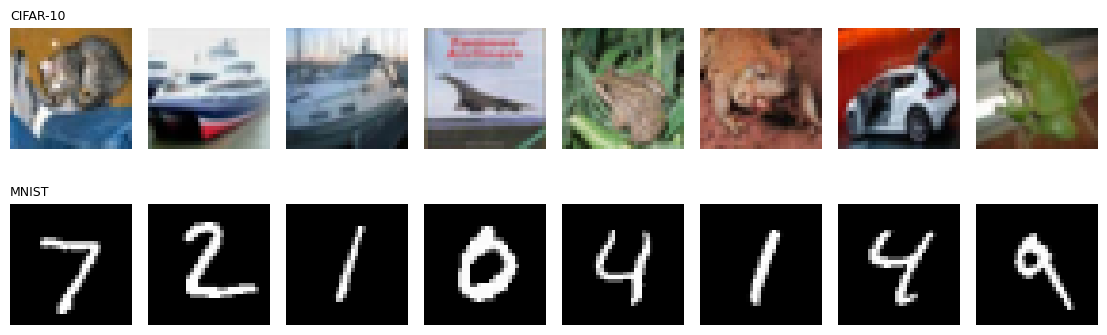

In [5]:
# Load both datasets once and move them to the device. They fit in GPU memory
# (about 1.6 GB together), which makes every experiment much faster.
data = {key: value.to(device) for key, value in load_cifar10().items()}
mnist = {key: value.to(device) for key, value in load_mnist().items()}
for name, dataset in [('CIFAR-10', data), ('MNIST', mnist)]:
    print(name, {key: tuple(value.shape) for key, value in dataset.items()})
show_images([data['x_test'][:8], mnist['x_test'][:8]], ['CIFAR-10', 'MNIST'])
plt.show()


#### Provided: Data Augmentation

Every fine-tuning run in Part 1 uses random crops of the image padded by 4
pixels and, on CIFAR-10, random horizontal flips, sampled independently for
every image of a batch on the GPU. On MNIST the flips are turned off, because a
mirrored digit may no longer be the same digit.

**Lecture Connection**

> Augmentation creates modified views of training samples  
> Appropriate augmentation can improve generalization  
> *(Lec03 Convolutional Neural Networks, p. 34)*

> Flipping may invalidate asymmetric semantic labels  
> *(Lec03 Convolutional Neural Networks, p. 35)*


In [6]:
def random_crop_flip(x, padding=4, flip=True):
    """Provided: random horizontal flip (if flip) and random crop after reflect padding, for every image of x."""
    n, c, h, w = x.shape
    if flip:
        flipped = torch.rand(n, device=x.device) < 0.5
        x = torch.where(flipped[:, None, None, None], x.flip(3), x)
    padded = F.pad(x, (padding,) * 4, mode='reflect')
    top = torch.randint(0, 2 * padding + 1, (n,), device=x.device)
    left = torch.randint(0, 2 * padding + 1, (n,), device=x.device)
    rows = (top[:, None] + torch.arange(h, device=x.device))[:, None, :, None]
    cols = (left[:, None] + torch.arange(w, device=x.device))[:, None, None, :]
    batch = torch.arange(n, device=x.device)[:, None, None, None]
    channel = torch.arange(c, device=x.device)[None, :, None, None]
    return padded[batch, channel, rows, cols]


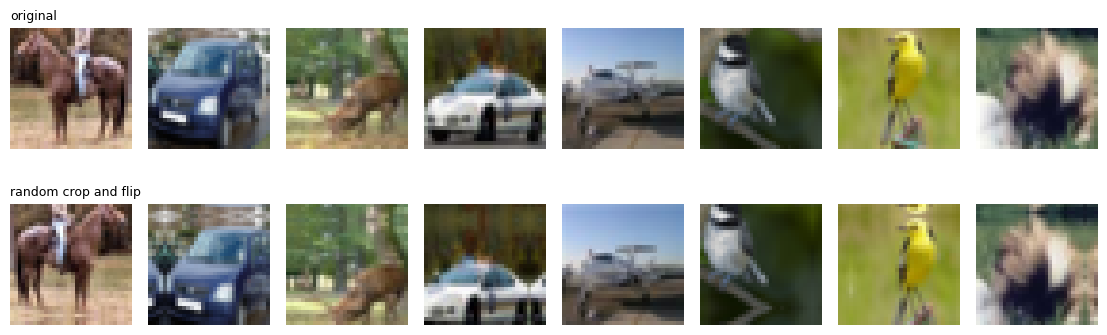

In [7]:
# Provided check: shapes, flips, and crops.
torch.manual_seed(SEED)
x = data['x_val'][:64]
x_aug = random_crop_flip(x)
assert x_aug.shape == x.shape
flipped_only = random_crop_flip(x, padding=0)   # without padding, only the flips remain
assert all(torch.equal(a, b) or torch.equal(a, b.flip(2)) for a, b in zip(flipped_only, x))
assert torch.equal(random_crop_flip(x, padding=0, flip=False), x)
show_images([x[:8], x_aug[:8]], ['original', 'random crop and flip'])
plt.show()


## Part 1: Transferring a Pretrained CNN (45 points)

A network trained on a large dataset has learned features that are useful
beyond its original task. Instead of training a network from random weights on
a small target dataset, we can start from such a pretrained network and adapt
it. In this part you will transfer a ResNet-18 trained on ImageNet (1.2 million
images of 1,000 classes) to CIFAR-10 and MNIST and compare how much of it to
train.

**Lecture Connection**

> Source learning process as prior knowledge acquisition  
> Target learning process as the new application  
> Transfer through features, representations, or parameters  
> *(Lec09 Transfer Learning and Adaptation, p. 4)*

> Training from scratch begins with randomly initialized parameters  
> A target task can start from pretrained parameters  
> Transfer benefits depend on the source and target tasks  
> *(Lec08 Pre-Training, p. 5)*

> Feature extraction with fixed pretrained parameters  
> Linear probing with a trainable prediction head  
> Full fine-tuning with end-to-end parameter updates  
> Selective fine-tuning of designated layers  
> *(Lec09 Transfer Learning and Adaptation, p. 6)*

**Concept Connection**

There are three common ways to use a pretrained convolutional network:

| Strategy | What is trained | In this assignment |
|---|---|---|
| fixed feature extractor | a linear classifier on the features of the frozen network | `linear` |
| fine-tuning | the new head and some or all of the pretrained layers | `last_block`, `full` |
| pretrained models as initialization | (released weights used as the starting point) | every pretrained run |

Training from random weights (`scratch`) is the reference. Which strategy works
best depends mainly on two factors: how large the target dataset is, and how
similar it is to the pretraining data. Because the early layers of a network
compute generic features and the later layers features specific to the
pretraining classes, four rules of thumb are commonly used:

| Target dataset | Similar to the pretraining data | Very different |
|---|---|---|
| small | linear classifier on the features of the last layer | linear classifier on features from an earlier layer |
| large | fine-tune through the full network | fine-tune through the full network (training from scratch becomes feasible) |

You will vary the size with the number of labeled images, and the similarity
with two target datasets: CIFAR-10, whose photos of animals and vehicles
resemble ImageNet, and MNIST, whose grayscale handwritten digits do not.

ImageNet models expect images of about 224x224 pixels. To keep the runtime
short, every ResNet-18 in this assignment resizes the 32x32 images to 64x64 and
normalizes them with the ImageNet mean and standard deviation.


### Section 1: Pretrained Models and Frozen Features


#### Question 1.1: Building a Transfer Model [code] (10 points)

Build a ResNet-18 with a new head for CIFAR-10, freeze the parts of it that a
transfer strategy does not train, and make sure that the frozen batch
normalization layers keep their pretrained statistics.

**Lecture Connection**

> requires_grad_(False) for frozen parameter gradients  
> eval() for evaluation-specific layer behavior  
> Separate control of freezing and model modes  
> *(Lec09 Transfer Learning and Adaptation, p. 9)*

> Batch statistics normalize intermediate activations during training  
> Running statistics are used during inference  
> *(Lec03 Convolutional Neural Networks, p. 26)*

> Fewer updated parameters than full fine-tuning  
> Layer selection as an adaptation hyperparameter  
> *(Lec09 Transfer Learning and Adaptation, p. 18)*

> Early layers often respond to edges and local contrasts  
> Deeper layers represent more task specific structures  
> *(Lec03 Convolutional Neural Networks, p. 22)*

**Concept Connection**

ResNet-18 consists of a stem (`conv1`, `bn1`, max pooling), four stages of
residual blocks (`layer1` to `layer4`), global average pooling, and a final
linear layer `fc` that predicts the 1,000 ImageNet classes. The ImageNet head is
useless for CIFAR-10, so it is replaced by a new randomly initialized head with
10 outputs. The deeper a layer, the more specific its features are to the
pretraining task, which is why fine-tuning often starts with the last stage.

A frozen layer must also keep its batch normalization statistics. In training
mode, `nn.BatchNorm2d` normalizes with the statistics of the current batch and
updates its running mean and variance, even if its weights do not require
gradients. Frozen batch normalization layers therefore stay in evaluation mode
during training.

| `mode` | Trainable parameters |
|---|---|
| `scratch` | all (the model has random weights) |
| `linear` | the head only |
| `last_block` | `backbone.layer4` and the head |
| `full` | all |

**Implementation Guide and Point Breakdown**

- **`TransferResNet.__init__` (3 points):** `torchvision.models.resnet18`
  takes the argument `weights`.
- **`configure_transfer` (4 points):** Set `requires_grad` of every parameter.
- **`set_train_mode` (3 points):** `module.weight.requires_grad` tells you
  whether a batch normalization layer is frozen.

| Tensor | Shape |
|---|---|
| `x` | `(N, 3, 32, 32)` |
| `model.prepare(x)` | `(N, 3, 64, 64)` |
| `model.features(x)` | `(N, 512)` |
| `model.features(x, layer=3)` | `(N, 256)` |
| `model(x)` | `(N, 10)` |

**Expected Check:** The pretrained backbone has the ImageNet weights and the
random one does not; the outputs have the shapes above; each mode has the
expected number of trainable parameters; and in training mode, exactly the
batch normalization layers of the frozen parts are in evaluation mode and keep
their running statistics.


In [8]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406])
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225])
INPUT_SIZE = 64
TRANSFER_MODES = ('scratch', 'linear', 'last_block', 'full')


class TransferResNet(nn.Module):
    """ResNet-18 backbone (512-dimensional features) with a new linear head."""

    def __init__(self, pretrained=True, num_classes=10):
        super().__init__()
        self.register_buffer('mean', IMAGENET_MEAN.view(1, 3, 1, 1).clone())
        self.register_buffer('std', IMAGENET_STD.view(1, 3, 1, 1).clone())
        ########################################################################
        # TODO 1.1 (3/10 points): Create a torchvision ResNet-18 as            #
        # self.backbone, with the ImageNet weights                             #
        # ResNet18_Weights.IMAGENET1K_V1 if pretrained is True and random      #
        # weights otherwise. Replace its final layer fc with nn.Identity, so   #
        # that the backbone returns 512-dimensional features, and create a new #
        # linear head self.head that maps them to num_classes scores.          #
        ########################################################################
        weights = (
        torchvision.models.ResNet18_Weights.IMAGENET1K_V1
        if pretrained else None
        )
        self.backbone = torchvision.models.resnet18(weights=weights)

        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.head = nn.Linear(in_features, num_classes)
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

    def prepare(self, x):
        """Provided: resize to INPUT_SIZE and normalize with the ImageNet statistics."""
        x = F.interpolate(x, size=INPUT_SIZE, mode='bilinear', align_corners=False)
        return (x - self.mean) / self.std

    def features(self, x, layer=4):
        """Provided: globally average-pooled output of backbone.layer4 (512 values) or backbone.layer3 (256)."""
        if layer == 4:
            return self.backbone(self.prepare(x))
        b = self.backbone
        h = b.maxpool(b.relu(b.bn1(b.conv1(self.prepare(x)))))
        return b.layer3(b.layer2(b.layer1(h))).mean(dim=(2, 3))

    def forward(self, x):
        return self.head(self.features(x))


def configure_transfer(model, mode):
    """Freeze or unfreeze the parameters of model (a TransferResNet) for a mode in TRANSFER_MODES."""
    assert mode in TRANSFER_MODES, mode
    ############################################################################
    # TODO 1.1 (4/10 points): Set requires_grad of every parameter according   #
    # to the mode, as described in the table above. The head is always         #
    # trainable.                                                               #
    ############################################################################
    train_all = mode in ('scratch', 'full')
    for parameter in model.parameters():
        parameter.requires_grad_(train_all)

    if mode == 'last_block':
        for parameter in model.backbone.layer4.parameters():
            parameter.requires_grad_(True)

    for parameter in model.head.parameters():
        parameter.requires_grad_(True)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################


def set_train_mode(model):
    """Training mode for the trainable parts; frozen batch normalization layers stay in evaluation mode."""
    ############################################################################
    # TODO 1.1 (3/10 points): Put the model in training mode, then put back    #
    # into evaluation mode every nn.BatchNorm2d layer whose parameters are     #
    # frozen.                                                                  #
    ############################################################################
    model.train()

    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            if not module.weight.requires_grad:
                module.eval()
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################


def count_parameters(module, trainable_only=True):
    """Provided: number of (trainable) parameters of a module."""
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


In [9]:
# Provided check: pretrained weights, shapes, trainable parameters, and batch normalization modes.
torch.manual_seed(SEED)
model = TransferResNet(pretrained=True).to(device)
reference = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1).to(device)
assert isinstance(model.backbone.fc, nn.Identity), 'replace backbone.fc by nn.Identity'
assert torch.equal(model.backbone.conv1.weight, reference.conv1.weight), 'load the ImageNet weights'
assert torch.equal(model.backbone.layer4[1].bn2.running_var, reference.layer4[1].bn2.running_var)
assert not torch.equal(TransferResNet(pretrained=False).to(device).backbone.conv1.weight, reference.conv1.weight)
x = data['x_val'][:4]
print('prepare:', tuple(model.prepare(x).shape), 'features:', tuple(model.features(x).shape),
      'logits:', tuple(model(x).shape))
assert model.prepare(x).shape == (4, 3, 64, 64)
assert model.features(x).shape == (4, 512) and model(x).shape == (4, 10)
assert model.features(x, layer=3).shape == (4, 256)
del reference

expected = {'scratch': 11181642, 'linear': 5130, 'last_block': 8398858, 'full': 11181642}
for mode, count in expected.items():
    configure_transfer(model, mode)
    print(f'{mode:10s}: {count_parameters(model):>10,d} trainable of {count_parameters(model, False):,d}')
    assert count_parameters(model) == count, mode

configure_transfer(model, 'last_block')
set_train_mode(model)
assert model.training and model.head.training
assert not model.backbone.bn1.training and not model.backbone.layer3[1].bn2.training
assert model.backbone.layer4[0].bn1.training and model.backbone.layer4[1].bn2.training

configure_transfer(model, 'linear')
set_train_mode(model)
assert all(not m.training for m in model.backbone.modules() if isinstance(m, nn.BatchNorm2d))
before = model.backbone.layer2[0].bn1.running_mean.clone()
model(data['x_val'][:64])
assert torch.equal(before, model.backbone.layer2[0].bn1.running_mean), 'frozen BN statistics changed'

configure_transfer(model, 'full')
set_train_mode(model)
assert all(m.training for m in model.modules())
del model
print('TransferResNet, configure_transfer, and set_train_mode check passed')


prepare: (4, 3, 64, 64) features: (4, 512) logits: (4, 10)
scratch   : 11,181,642 trainable of 11,181,642
linear    :      5,130 trainable of 11,181,642
last_block:  8,398,858 trainable of 11,181,642
full      : 11,181,642 trainable of 11,181,642
TransferResNet, configure_transfer, and set_train_mode check passed


#### Question 1.2: Frozen Features and a Linear Classifier [code] (10 points)

Use the frozen ResNet-18 as a fixed feature extractor: compute the features of
all images once, train a linear classifier on them, and compare the features of
the last and an earlier stage of the pretrained network with those of a
randomly initialized one, on both target datasets and for different amounts of
labeled data.

**Lecture Connection**

> Input transformation through a pretrained encoder  
> Fixed encoder parameters during feature extraction  
> Feature vectors as inputs to downstream models  
> *(Lec09 Transfer Learning and Adaptation, p. 8)*

> Trainable linear prediction head  
> Supervised cross-entropy objective  
> Linear accessibility of target-class information  
> *(Lec09 Transfer Learning and Adaptation, p. 10)*

> Extract encoder features without gradient tracking  
> *(Lec07 Representation Learning, p. 43)*

**Concept Connection**

Because the backbone is never updated, its features can be computed once and
reused for every training epoch, which makes this the cheapest strategy: each
epoch only trains a linear layer with 5,130 parameters. As in Assignment 5,
the provided code standardizes the features with the mean and standard
deviation of the training features, keeps the classifier from the epoch with
the best validation accuracy, and evaluates it once on the test features.

The provided `model.features(x, layer)` returns the globally average-pooled
output of the last stage (`layer=4`, 512 values) or of the stage before it
(`layer=3`, 256 values). Features from an earlier stage are more generic and
may transfer better to a target dataset that is very different from the
pretraining data.

**Implementation Guide and Point Breakdown**

- **`extract_features` (3 points):** The function is decorated with
  `@torch.no_grad()`.
- **One epoch of training (4 points):** Log `step` and `loss` for every
  iteration.
- **Epoch evaluation (3 points):** Log `epoch`, `train_acc`, and `val_acc`.

| Tensor | Shape |
|---|---|
| `x` | `(N, 3, 32, 32)` |
| `features` | `(N, 512)` (`layer=4`) or `(N, 256)` (`layer=3`) |
| classifier output | `(N, 10)` |

**Expected Check:** `extract_features` matches one direct call for both layers
and leaves the model in evaluation mode, and on ten well-separated Gaussian
clusters the linear classifier reaches a test accuracy of at least `0.95` and
logs the keys above with one row per iteration and one row per epoch.


In [10]:
@torch.no_grad()
def extract_features(model, x, layer=4, batch_size=500):
    """
    Inputs:
    - model: TransferResNet
    - x: images of shape (N, 3, 32, 32)
    - layer: 4 for the last stage of the backbone, 3 for the stage before it

    Returns:
    - features: tensor of shape (N, 512) for layer 4 or (N, 256) for layer 3
    """
    ############################################################################
    # TODO 1.2 (3/10 points): Put the model in evaluation mode, apply          #
    # model.features with the given layer to x in chunks of batch_size, and    #
    # concatenate the outputs into one tensor named `features`.                #
    ############################################################################
    model.eval()

    feature_batches = []
    for start in range(0, len(x), batch_size):
        x_batch = x[start:start + batch_size]
        batch_features = model.features(x_batch, layer=layer)
        feature_batches.append(batch_features)

    features = torch.cat(feature_batches, dim=0)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return features


@torch.no_grad()
def accuracy(model, x, y):
    """Provided: classification accuracy of a TransferResNet (Python float)."""
    return (model.head(extract_features(model, x)).argmax(dim=1) == y).float().mean().item()


def linear_classifier(train_feats, train_labels, val_feats, val_labels, test_feats, test_labels,
                      name, num_epochs=30, lr=1e-3, batch_size=256, num_classes=10):
    """
    Train a linear classifier on frozen features.

    Returns:
    - log: TrainingLog of the run (saved to logs/)
    - test_acc: test accuracy of the classifier from the epoch with the best
      validation accuracy (Python float)
    """
    torch.manual_seed(SEED)
    mean, std = train_feats.mean(dim=0), train_feats.std(dim=0) + 1e-6
    train_feats, val_feats, test_feats = [(f - mean) / std for f in (train_feats, val_feats, test_feats)]
    classifier = nn.Linear(train_feats.shape[1], num_classes).to(train_feats.device)
    optimizer = torch.optim.AdamW(classifier.parameters(), lr=lr, weight_decay=1e-4)
    train_loader = TensorLoader(train_feats, train_labels, batch_size, shuffle=True)
    log = TrainingLog(name)
    step = 0
    best_val_acc, best_state = -1.0, None

    for epoch in range(1, num_epochs + 1):
        ########################################################################
        # TODO 1.2 (4/10 points): Train the classifier for one epoch on        #
        # train_loader with F.cross_entropy, and log one row per iteration     #
        # with log.log_step using the keys step and loss.                      #
        ########################################################################
        classifier.train()

        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()

            logits = classifier(x_batch)
            loss = F.cross_entropy(logits, y_batch)

            loss.backward()
            optimizer.step()

            step += 1
            log.log_step(step=step, loss=loss.item())
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

        ########################################################################
        # TODO 1.2 (3/10 points): Without gradient tracking, compute the       #
        # accuracy on all training and all validation features, and log one    #
        # row with log.log_epoch using the keys epoch, train_acc, and val_acc. #
        ########################################################################
        classifier.eval()

        with torch.no_grad():
            train_predictions = classifier(train_feats).argmax(dim=1)
            val_predictions = classifier(val_feats).argmax(dim=1)

            train_acc = (
                (train_predictions == train_labels).float().mean().item()
            )
            val_acc = (
                (val_predictions == val_labels).float().mean().item()
            )

        log.log_epoch(
            epoch=epoch,
            train_acc=train_acc,
            val_acc=val_acc,
        )
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

        if log.epochs['val_acc'][-1] > best_val_acc:
            best_val_acc = log.epochs['val_acc'][-1]
            best_state = {k: v.clone() for k, v in classifier.state_dict().items()}

    classifier.load_state_dict(best_state)
    with torch.no_grad():
        test_acc = (classifier(test_feats).argmax(dim=1) == test_labels).float().mean().item()
    log.save()
    return log, test_acc


In [11]:
# Provided check: extract_features and the linear classifier.
torch.manual_seed(SEED)
model = TransferResNet(pretrained=True).to(device)
model.train()
x = data['x_val'][:50]
features = extract_features(model, x, batch_size=16)
assert not model.training, 'extract_features should put the model in evaluation mode'
assert features.shape == (50, 512)
with torch.no_grad():
    assert torch.allclose(features, model.features(x), rtol=1e-2, atol=1e-2)
    features3 = extract_features(model, x, layer=3, batch_size=16)
    assert features3.shape == (50, 256)
    assert torch.allclose(features3, model.features(x, layer=3), rtol=1e-2, atol=1e-2)
del model

torch.manual_seed(SEED)
centers = 4 * torch.randn(10, 16, device=device)


def gaussian_clusters(n):
    labels = torch.arange(n, device=device) % 10
    return centers[labels] + torch.randn(n, 16, device=device), labels


(tr_f, tr_y), (va_f, va_y), (te_f, te_y) = gaussian_clusters(500), gaussian_clusters(200), gaussian_clusters(200)
toy_log, toy_test_acc = linear_classifier(tr_f, tr_y, va_f, va_y, te_f, te_y, name='check_linear',
                                        num_epochs=30, lr=1e-2)
reloaded = TrainingLog.load('check_linear')
print('toy test accuracy:', toy_test_acc)
assert toy_test_acc >= 0.95
assert set(reloaded.steps) == {'step', 'loss'}
assert set(reloaded.epochs) == {'epoch', 'train_acc', 'val_acc'}
assert len(reloaded.steps['loss']) == 30 * 2 and len(reloaded.epochs['val_acc']) == 30
print('extract_features and linear_classifier check passed')


toy test accuracy: 1.0
extract_features and linear_classifier check passed


#### Provided: Frozen Features across Layers, Datasets, and Label Budgets

The cell below extracts three kinds of frozen features of all images of both
datasets: the last stage (`layer4`) and the stage before it (`layer3`) of the
pretrained ResNet-18, and the last stage of a randomly initialized ResNet-18 of
the same architecture. It trains a linear classifier on each with 5, 50, 500,
and 4,000 labeled images per class. Smaller label budgets are trained for more
epochs, so that every run takes a similar number of iterations. The results are
saved to `logs/frozen_features.csv`, and you will use them in Question 1.4.

**Lecture Connection**

> Comparison with a simple target-task baseline  
> Limited correction of task-specific representation mismatch  
> *(Lec09 Transfer Learning and Adaptation, p. 13)*

> Frozen features as a low-cost baseline  
> Domain mismatch as an additional decision factor  
> *(Lec09 Transfer Learning and Adaptation, p. 41)*

**Expected Check:** On CIFAR-10, the pretrained `layer4` features are at least
`0.2` more accurate than the random features with every label budget; on
MNIST, they are less than `0.1` more accurate with every budget, and the
pretrained `layer3` features are more accurate than the pretrained `layer4`
features with every budget.


                                   5      50     500    4000  (labeled images per class)
cifar10  pretrained_layer4  test   0.497   0.650   0.729   0.764   [12s]
cifar10  pretrained_layer3  test   0.465   0.655   0.755   0.792   [14s]
cifar10  random_layer4      test   0.215   0.305   0.392   0.445   [15s]
mnist    pretrained_layer4  test   0.605   0.868   0.948   0.966   [12s]
mnist    pretrained_layer3  test   0.820   0.946   0.976   0.985   [10s]
mnist    random_layer4      test   0.652   0.858   0.936   0.959   [16s]


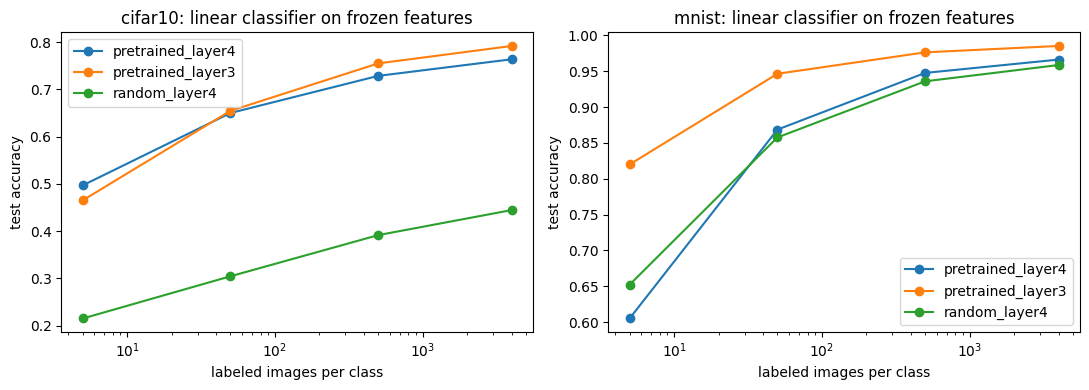

In [12]:
# Provided: linear classifiers on frozen features of two layers, two datasets, and four label budgets.
LABEL_BUDGETS = {5: 300, 50: 200, 500: 50, 4000: 20}   # labeled images per class -> epochs
FEATURE_SETS = [   # name, pretrained, layer
    ('pretrained_layer4', True, 4),
    ('pretrained_layer3', True, 3),
    ('random_layer4', False, 4),
]
frozen_rows = []
print(' ' * 28 + ''.join(f'{per_class:>8d}' for per_class in LABEL_BUDGETS) + '  (labeled images per class)')
for dataset_name, dataset in [('cifar10', data), ('mnist', mnist)]:
    for feature_set, pretrained, layer in FEATURE_SETS:
        start = time.time()
        torch.manual_seed(SEED)
        model = TransferResNet(pretrained).to(device)
        feats = {split: extract_features(model, dataset[f'x_{split}'], layer=layer)
                 for split in ['train', 'val', 'test']}
        del model
        accs = []
        for per_class, num_epochs in LABEL_BUDGETS.items():
            idx = balanced_subset(dataset['y_train'], per_class)
            log, test_acc = linear_classifier(
                feats['train'][idx], dataset['y_train'][idx], feats['val'], dataset['y_val'],
                feats['test'], dataset['y_test'], name=f'frozen_{dataset_name}_{feature_set}_{per_class}',
                num_epochs=num_epochs)
            frozen_rows.append({'dataset': dataset_name, 'features': feature_set, 'per_class': per_class,
                                'train_acc': log.epochs['train_acc'][-1], 'val_acc': max(log.epochs['val_acc']),
                                'test_acc': test_acc})
            accs.append(test_acc)
        print(f'{dataset_name:8s} {feature_set:18s} test' + ''.join(f'{a:8.3f}' for a in accs)
              + f'   [{time.time() - start:.0f}s]')
        del feats
save_table(frozen_rows, 'frozen_features')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, dataset_name in zip(axes, ['cifar10', 'mnist']):
    for i, (feature_set, _, _) in enumerate(FEATURE_SETS):
        rows = [r for r in frozen_rows if r['dataset'] == dataset_name and r['features'] == feature_set]
        ax.plot([r['per_class'] for r in rows], [r['test_acc'] for r in rows], 'o-', color=f'C{i}',
                label=feature_set)
    ax.set_xscale('log')
    ax.set_xlabel('labeled images per class')
    ax.set_ylabel('test accuracy')
    ax.set_title(f'{dataset_name}: linear classifier on frozen features')
    ax.legend()
fig.tight_layout()
plt.show()


In [13]:
# Provided check: the value of pretrained features depends on the target dataset and the layer.
acc = {(r['dataset'], r['features'], r['per_class']): r['test_acc'] for r in frozen_rows}
for per_class in LABEL_BUDGETS:
    assert acc[('cifar10', 'pretrained_layer4', per_class)] >= acc[('cifar10', 'random_layer4', per_class)] + 0.2
    assert acc[('mnist', 'pretrained_layer4', per_class)] < acc[('mnist', 'random_layer4', per_class)] + 0.1
    assert acc[('mnist', 'pretrained_layer3', per_class)] > acc[('mnist', 'pretrained_layer4', per_class)]
print('Frozen features check passed')


Frozen features check passed


### Section 2: Fine-Tuning


#### Question 1.3: Fine-Tuning with Logging [code] (15 points)

Fine-tune a `TransferResNet` end to end for a given transfer mode, with
separate learning rates for the head and the backbone. Besides the training and
validation accuracy, log how far the features of the backbone move away from
the features it had before fine-tuning.

**Lecture Connection**

> Pretrained parameters as target-model initialization  
> Joint optimization of the encoder and prediction head  
> Greater adaptation flexibility with higher training requirements  
> *(Lec09 Transfer Learning and Adaptation, p. 15)*

> Separate learning rates for encoder layers and head  
> Parameter-group configuration in AdamW  
> *(Lec09 Transfer Learning and Adaptation, p. 19)*

> Changes in pretrained feature representations  
> Possible loss of previously useful information  
> Dependence on learning rate, data, and training duration  
> *(Lec09 Transfer Learning and Adaptation, p. 17)*

> Validation performance identifies useful checkpoints  
> Best checkpoint should be restored before final testing  
> *(Lec06 Training and Generalization, p. 30)*

**Concept Connection**

The new head starts from random weights, but the backbone already computes
useful features. With **discriminative learning rates**, the optimizer uses a
smaller learning rate for the backbone than for the head, so that the
pretrained weights change only slowly while the head learns quickly. PyTorch
optimizers support this with **parameter groups**: a list of dictionaries, each
with its own `params` and `lr`.

To see how much fine-tuning changes the pretrained features, the log records
the **feature drift** on 500 fixed validation images `drift_x`:

$$
\text{drift} = 1 - \frac{1}{M}\sum_{i=1}^{M} \cos\big(f_\theta(x_i), f_{\theta_0}(x_i)\big),
$$

where $f_{\theta_0}$ are the features before fine-tuning (`ref_feats`) and
$f_\theta$ the current ones. A drift of 0 means that the features have not
changed; a frozen backbone always has a drift of 0.

**Implementation Guide and Point Breakdown**

The provided code configures the model, builds the loader of the labeled
training images, computes `ref_feats`, keeps the model state from the epoch
with the best validation accuracy, restores it at the end, and evaluates it on
the test set.

- **`make_optimizer` (4 points):** Use `torch.optim.AdamW` with a list of
  parameter groups.
- **`feature_drift` (3 points):** Use `extract_features`; do not use
  `F.cosine_similarity`.
- **Training iteration (3 points):** The provided code already calls
  `set_train_mode` at the start of every epoch. `augment` is
  `random_crop_flip` by default. Log `step` and `loss`.
- **Epoch evaluation (5 points):** Use the provided `accuracy` and the
  validation set of `dataset` (CIFAR-10 by default). Log `epoch`,
  `train_acc`, `val_acc`, and `drift`.

| Logged per | Keys |
|---|---|
| iteration | `step`, `loss` |
| epoch | `epoch`, `train_acc`, `val_acc`, `drift` |

**Expected Check:** The optimizer contains exactly the trainable parameters
with the requested learning rates; `feature_drift` is 0 for unchanged features
and 2 for opposite features; and a short run of the `linear` mode changes only
the head, keeps the batch normalization statistics, writes the log keys above,
and returns the model from the best validation epoch.


In [14]:
def make_optimizer(model, head_lr, backbone_lr=None, weight_decay=1e-4):
    """AdamW over the trainable parameters of model, with one learning rate for the head and one for the backbone."""
    ############################################################################
    # TODO 1.3 (4/15 points): Create an AdamW optimizer with weight decay      #
    # weight_decay and up to two parameter groups: the trainable head          #
    # parameters with learning rate head_lr, and the trainable backbone        #
    # parameters with learning rate backbone_lr (head_lr if backbone_lr is     #
    # None). Leave out frozen parameters, and leave out the backbone group if  #
    # it is empty.                                                             #
    ############################################################################
    head_params = [
        p for p in model.head.parameters() if p.requires_grad
    ]
    backbone_params = [
        p for p in model.backbone.parameters() if p.requires_grad
    ]

    param_groups = [
        {'params': head_params, 'lr': head_lr}
    ]

    if backbone_params:
        param_groups.append({
            'params': backbone_params,
            'lr': head_lr if backbone_lr is None else backbone_lr,
        })

    optimizer = torch.optim.AdamW(
        param_groups,
        weight_decay=weight_decay,
    )
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return optimizer


def feature_drift(model, probe_x, ref_feats):
    """1 - mean cosine similarity between the current features of probe_x and ref_feats (Python float)."""
    ############################################################################
    # TODO 1.3 (3/15 points): Extract the current features of probe_x and      #
    # compute one minus the mean cosine similarity between each current        #
    # feature vector and the corresponding row of ref_feats (Python float).    #
    ############################################################################
    current_feats = extract_features(model, probe_x)

    current_normalized = F.normalize(current_feats, p=2, dim=1)
    reference_normalized = F.normalize(ref_feats, p=2, dim=1)

    similarities = (
        current_normalized * reference_normalized
    ).sum(dim=1)

    drift = (1.0 - similarities.mean()).item()
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return drift


def finetune(model, mode, name, train_idx, num_epochs, head_lr=1e-3, backbone_lr=None, batch_size=128,
             dataset=None, augment=random_crop_flip, drift_x=None, verbose=True):
    """
    Fine-tune model (a TransferResNet) on the labeled training images train_idx
    of dataset (CIFAR-10 by default). drift_x defaults to the first 500
    validation images of dataset.

    Returns:
    - log: TrainingLog of the run (saved to logs/)
    - result: dict with the best validation accuracy, its epoch, and the test
      accuracy of the restored model
    """
    torch.manual_seed(SEED)
    configure_transfer(model, mode)
    optimizer = make_optimizer(model, head_lr, backbone_lr)
    dataset = data if dataset is None else dataset
    drift_x = dataset['x_val'][:500] if drift_x is None else drift_x
    x_labeled, y_labeled = dataset['x_train'][train_idx], dataset['y_train'][train_idx]
    loader = TensorLoader(x_labeled, y_labeled, batch_size, shuffle=True)
    ref_feats = extract_features(model, drift_x)
    log = TrainingLog(name)
    step = 0
    best_val_acc, best_epoch, best_state = -1.0, 0, None

    for epoch in range(1, num_epochs + 1):
        set_train_mode(model)
        for x, y in loader:
            ####################################################################
            # TODO 1.3 (3/15 points): Apply augment to x, compute the cross-   #
            # entropy loss of the model, update the trainable parameters, and  #
            # log one row with log.log_step using the keys step and loss.      #
            ####################################################################
            optimizer.zero_grad()

            x_augmented = augment(x)
            logits = model(x_augmented)
            loss = F.cross_entropy(logits, y)

            loss.backward()
            optimizer.step()

            log.log_step(step=step, loss=loss.item())
            ####################################################################
            #                         END OF YOUR CODE                         #
            ####################################################################
            step += 1

        ########################################################################
        # TODO 1.3 (5/15 points): Log one row with log.log_epoch using the     #
        # keys epoch, train_acc (accuracy on the labeled training images       #
        # without augmentation), val_acc (accuracy on the validation set of    #
        # dataset), and drift (feature_drift of drift_x against ref_feats).    #
        ########################################################################
        train_acc = accuracy(model, x_labeled, y_labeled)
        val_acc = accuracy(
            model,
            dataset['x_val'],
            dataset['y_val'],
        )
        drift = feature_drift(model, drift_x, ref_feats)

        log.log_epoch(
            epoch=epoch,
            train_acc=train_acc,
            val_acc=val_acc,
            drift=drift,
        )
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

        if log.epochs['val_acc'][-1] > best_val_acc:
            best_val_acc, best_epoch = log.epochs['val_acc'][-1], epoch
            best_state = copy.deepcopy(model.state_dict())
        if verbose and (epoch % 5 == 0 or epoch == num_epochs):
            print(f"[{name}] epoch {epoch:2d}/{num_epochs}: loss {log.steps['loss'][-1]:.3f}, "
                  f"train acc {log.epochs['train_acc'][-1]:.3f}, val acc {log.epochs['val_acc'][-1]:.3f}, "
                  f"drift {log.epochs['drift'][-1]:.3f}")

    model.load_state_dict(best_state)
    result = {'val_acc': best_val_acc, 'best_epoch': best_epoch,
              'test_acc': accuracy(model, dataset['x_test'], dataset['y_test'])}
    log.save()
    return log, result


In [15]:
# Provided check: parameter groups, feature drift, and a short fine-tuning run.
torch.manual_seed(SEED)
model = TransferResNet(pretrained=True).to(device)
configure_transfer(model, 'linear')
optimizer = make_optimizer(model, head_lr=1e-3)
assert len(optimizer.param_groups) == 1
assert sum(p.numel() for p in optimizer.param_groups[0]['params']) == 5130
configure_transfer(model, 'full')
optimizer = make_optimizer(model, head_lr=1e-3, backbone_lr=1e-4)
assert [g['lr'] for g in optimizer.param_groups] == [1e-3, 1e-4]
assert [sum(p.numel() for p in g['params']) for g in optimizer.param_groups] == [5130, 11176512]
assert optimizer.param_groups[0]['weight_decay'] == 1e-4
optimizer = make_optimizer(model, head_lr=1e-3)
assert [g['lr'] for g in optimizer.param_groups] == [1e-3, 1e-3]
configure_transfer(model, 'last_block')
optimizer = make_optimizer(model, head_lr=1e-3, backbone_lr=1e-4)
assert sum(p.numel() for p in optimizer.param_groups[1]['params']) == 8393728

probe_x = data['x_val'][:64]
ref = extract_features(model, probe_x)
assert abs(feature_drift(model, probe_x, ref)) < 1e-5
assert abs(feature_drift(model, probe_x, -ref) - 2.0) < 1e-5
assert abs(feature_drift(model, probe_x, 3 * ref)) < 1e-5

backbone_before = copy.deepcopy(model.backbone.state_dict())
head_before = model.head.weight.clone()
check_log, check_result = finetune(model, 'linear', 'check_finetune', balanced_subset(data['y_train'], 20),
                                   num_epochs=3, drift_x=probe_x)
reloaded = TrainingLog.load('check_finetune')
assert set(reloaded.steps) == {'step', 'loss'}
assert set(reloaded.epochs) == {'epoch', 'train_acc', 'val_acc', 'drift'}
assert len(reloaded.steps['loss']) == 3 * 2 and len(reloaded.epochs['drift']) == 3
assert all(torch.equal(v, model.backbone.state_dict()[k]) for k, v in backbone_before.items()), \
    'the linear mode must not change the backbone (weights or BN statistics)'
assert not torch.equal(head_before, model.head.weight)
assert max(reloaded.epochs['drift']) < 1e-5
assert abs(accuracy(model, data['x_val'], data['y_val']) - max(reloaded.epochs['val_acc'])) < 1e-6
print('check run:', check_result)
del model, optimizer
print('make_optimizer, feature_drift, and finetune check passed')


[check_finetune] epoch  3/3: loss 2.193, train acc 0.290, val acc 0.241, drift 0.000
check run: {'val_acc': 0.2409999966621399, 'best_epoch': 3, 'test_acc': 0.24129998683929443}
make_optimizer, feature_drift, and finetune check passed


#### Provided: Comparing Transfer Strategies

The cell below compares five strategies on CIFAR-10 and on MNIST, each with 50
and 500 labeled images per class (about 1% and 10% of the training set). All
runs use AdamW with a head learning rate of `1e-3` and random crops (and flips
on CIFAR-10); `full_low_lr` uses a backbone learning rate of `1e-4`. With 50
images per class, the runs are trained for 40 epochs; with 500, for 15 epochs.
The plots show the logs of every run, and the results are saved to
`logs/transfer_comparison.csv`. The model of `full_low_lr` with 500 CIFAR-10
images per class is kept for Section 5. You will interpret these results in
Question 1.4.

| Strategy | Initialization | Trainable | Backbone learning rate |
|---|---|---|---|
| `scratch` | random | all | `1e-3` |
| `linear` | ImageNet | head | — |
| `last_block` | ImageNet | `layer4` and head | `1e-3` |
| `full` | ImageNet | all | `1e-3` |
| `full_low_lr` | ImageNet | all | `1e-4` |

**Lecture Connection**

> Smaller encoder learning rates  
> Selective or gradual unfreezing  
> *(Lec09 Transfer Learning and Adaptation, p. 22)*

> Negative transfer as poorer target performance caused by transferred knowledge  
> Scratch-trained target models as possible negative-transfer baselines  
> *(Lec09 Transfer Learning and Adaptation, p. 23)*

> Training validation gaps reveal possible overfitting  
> *(Lec06 Training and Generalization, p. 28)*

**Expected Check:** On CIFAR-10 with both label budgets, every pretrained
strategy is more accurate on the test set than `scratch`, `full_low_lr` is at
least as accurate as `full`, and `full` drifts more than `full_low_lr`. On
MNIST with 50 images per class, `scratch` is more accurate than `linear`, and
with both budgets `full` and `full_low_lr` are more accurate than `linear`. The
backbone of `linear` never drifts.


cifar10_scratch_50       best val 0.420 (epoch 32) | test 0.411 | final train 0.968 | drift 0.450 | 34s
cifar10_linear_50        best val 0.668 (epoch 28) | test 0.651 | final train 0.918 | drift 0.000 | 31s
cifar10_last_block_50    best val 0.693 (epoch 21) | test 0.685 | final train 0.996 | drift 0.515 | 36s
cifar10_full_50          best val 0.656 (epoch 18) | test 0.657 | final train 0.966 | drift 0.568 | 38s
cifar10_full_low_lr_50   best val 0.707 (epoch 40) | test 0.704 | final train 1.000 | drift 0.378 | 39s
cifar10_scratch_500      best val 0.631 (epoch 15) | test 0.617 | final train 0.726 | drift 0.382 | 49s
cifar10_linear_500       best val 0.727 (epoch 10) | test 0.723 | final train 0.782 | drift 0.000 | 28s
cifar10_last_block_500   best val 0.814 (epoch  8) | test 0.803 | final train 0.982 | drift 0.556 | 34s
cifar10_full_500         best val 0.792 (epoch 10) | test 0.771 | final train 0.914 | drift 0.563 | 49s
cifar10_full_low_lr_500  best val 0.836 (epoch 13) | test 0.827 

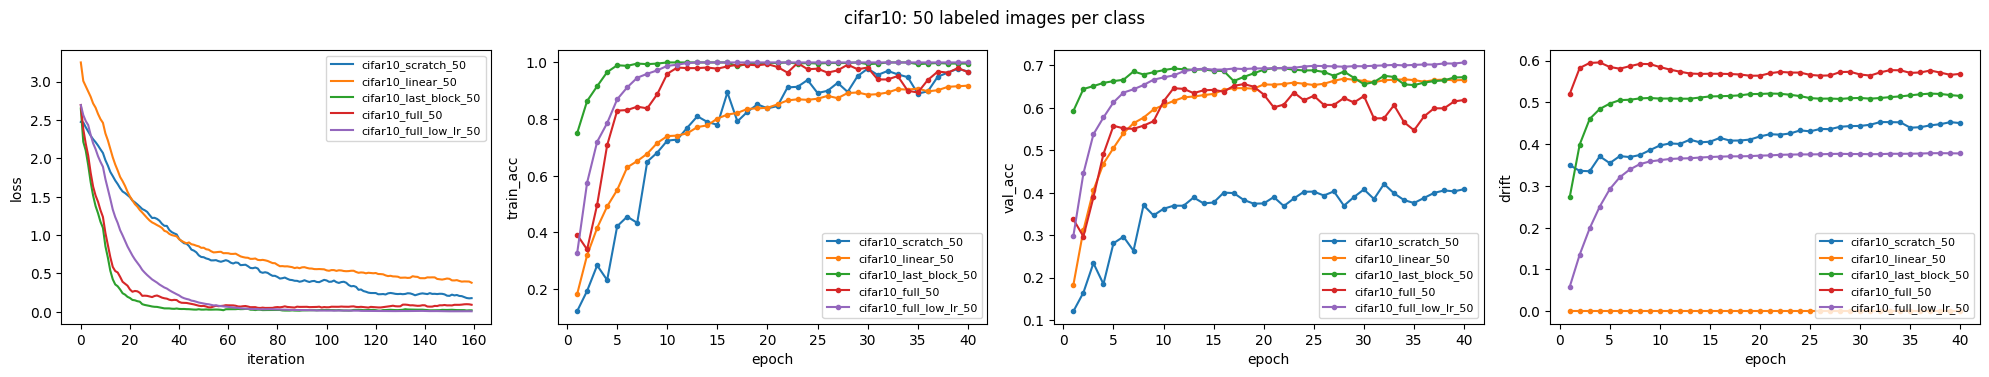

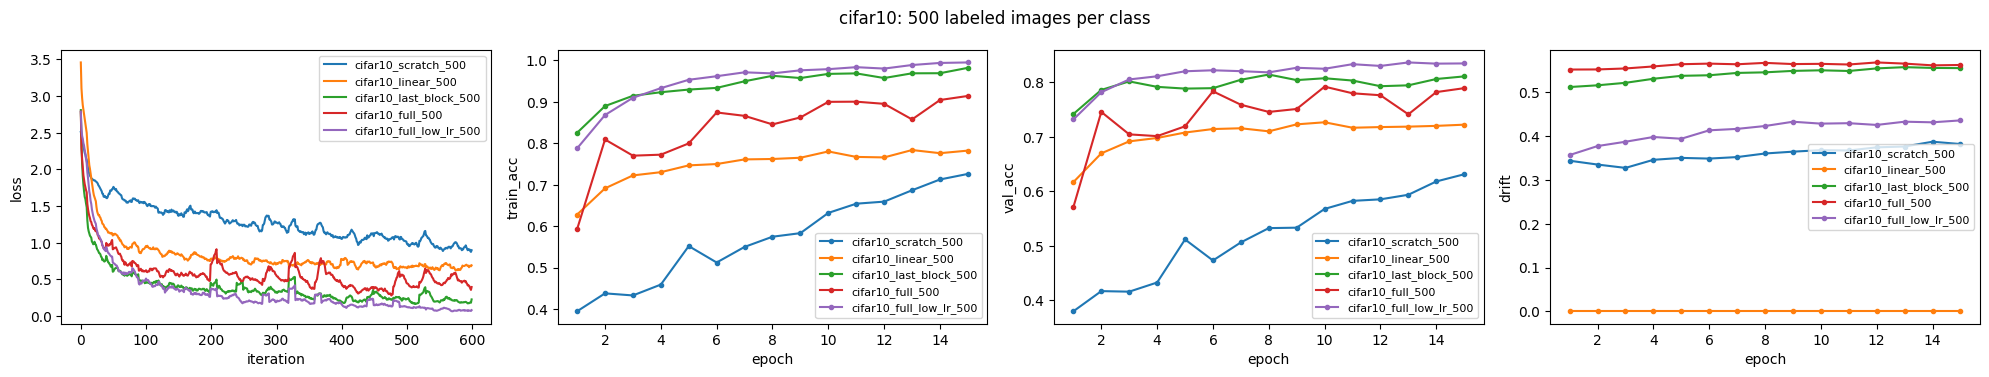

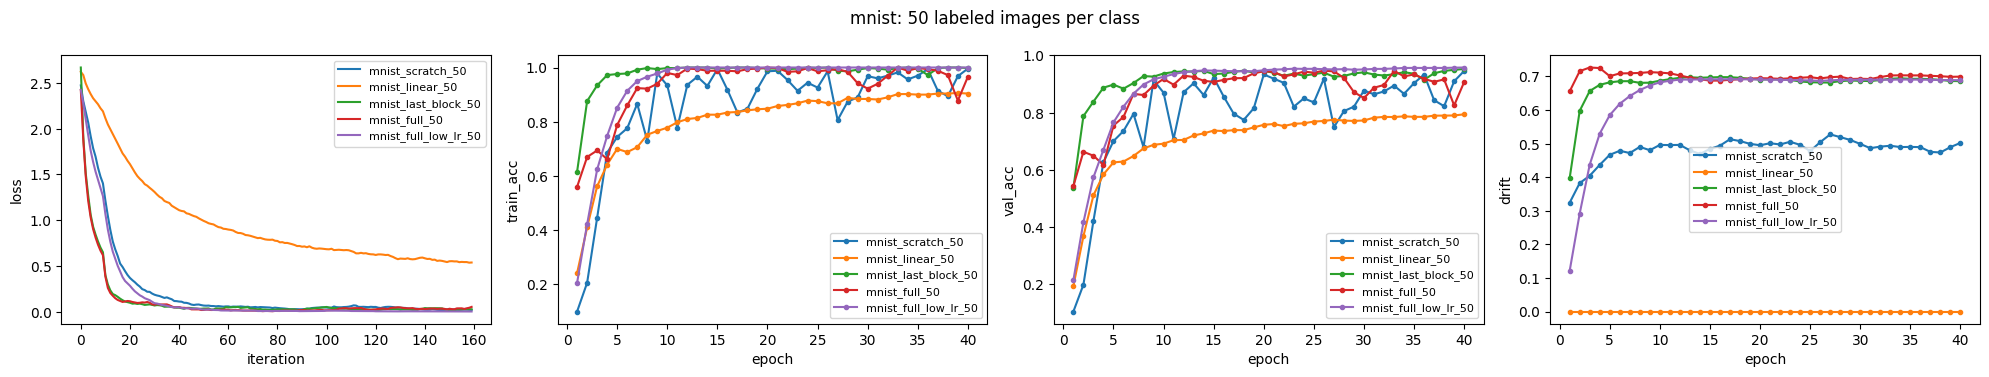

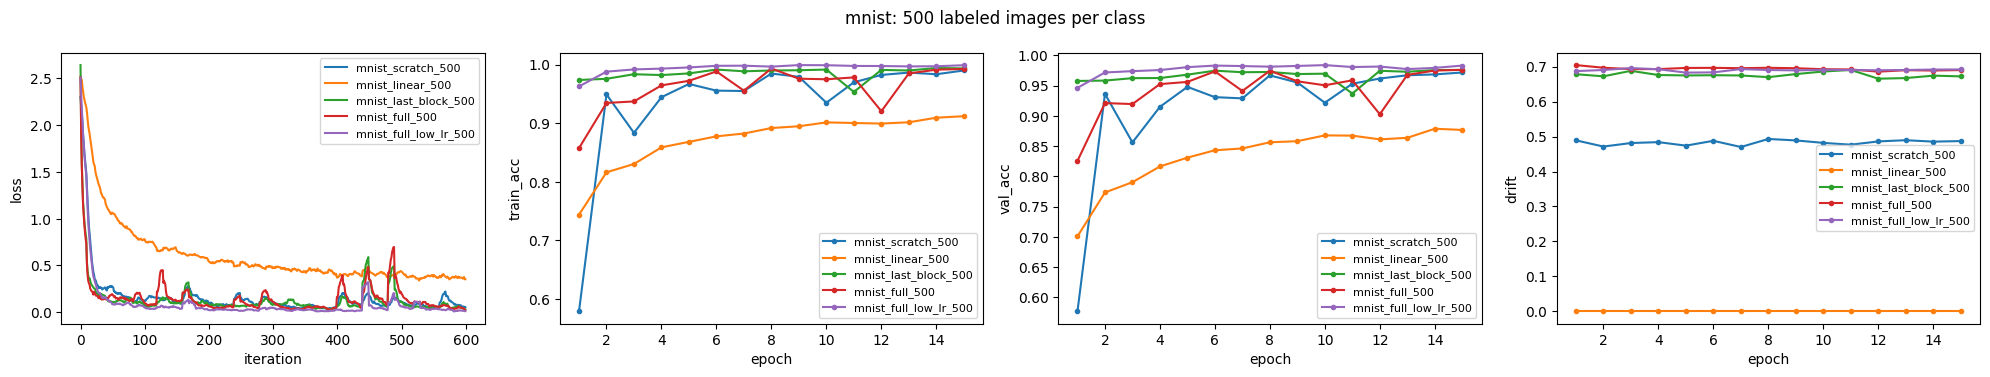

In [16]:
# Provided: five transfer strategies with two label budgets.
STRATEGIES = [   # name, pretrained, mode, backbone learning rate
    ('scratch', False, 'scratch', None),
    ('linear', True, 'linear', None),
    ('last_block', True, 'last_block', None),
    ('full', True, 'full', None),
    ('full_low_lr', True, 'full', 1e-4),
]
FINETUNE_BUDGETS = {50: 40, 500: 15}   # labeled images per class -> epochs
TARGETS = {   # dataset name -> (dataset, augmentation)
    'cifar10': (data, random_crop_flip),
    'mnist': (mnist, lambda x: random_crop_flip(x, flip=False)),
}

transfer_logs, transfer_rows = {}, []
for dataset_name, (dataset, augment) in TARGETS.items():
    for per_class, num_epochs in FINETUNE_BUDGETS.items():
        train_idx = balanced_subset(dataset['y_train'], per_class)
        for strategy, pretrained, mode, backbone_lr in STRATEGIES:
            start = time.time()
            torch.manual_seed(SEED)
            model = TransferResNet(pretrained).to(device)
            name = f'{dataset_name}_{strategy}_{per_class}'
            log, result = finetune(model, mode, name, train_idx, num_epochs, backbone_lr=backbone_lr,
                                   dataset=dataset, augment=augment, verbose=False)
            transfer_logs[name] = log
            transfer_rows.append({'dataset': dataset_name, 'strategy': strategy, 'per_class': per_class,
                                  'trainable_params': count_parameters(model),
                                  'final_train_acc': log.epochs['train_acc'][-1], **result,
                                  'final_drift': log.epochs['drift'][-1],
                                  'seconds': round(time.time() - start, 1)})
            print(f"{name:24s} best val {result['val_acc']:.3f} (epoch {result['best_epoch']:2d}) | "
                  f"test {result['test_acc']:.3f} | final train {log.epochs['train_acc'][-1]:.3f} | "
                  f"drift {log.epochs['drift'][-1]:.3f} | {time.time() - start:.0f}s")
            if name == 'cifar10_full_low_lr_500':
                shift_model = model
            else:
                del model
save_table(transfer_rows, 'transfer_comparison')

for dataset_name in TARGETS:
    for per_class in FINETUNE_BUDGETS:
        plot_logs([transfer_logs[f'{dataset_name}_{s[0]}_{per_class}'] for s in STRATEGIES], step_keys=['loss'],
                  epoch_keys=['train_acc', 'val_acc', 'drift'], smooth=10,
                  title=f'{dataset_name}: {per_class} labeled images per class')
        plt.show()


In [17]:
# Provided check: the best strategy depends on the target dataset.
for per_class in FINETUNE_BUDGETS:
    rows = {r['strategy']: r for r in transfer_rows if r['dataset'] == 'cifar10' and r['per_class'] == per_class}
    for strategy in ['linear', 'last_block', 'full', 'full_low_lr']:
        assert rows[strategy]['test_acc'] > rows['scratch']['test_acc'], (per_class, strategy)
    assert rows['full_low_lr']['test_acc'] >= rows['full']['test_acc'], per_class
    assert rows['full']['final_drift'] > rows['full_low_lr']['final_drift'], per_class
    rows = {r['strategy']: r for r in transfer_rows if r['dataset'] == 'mnist' and r['per_class'] == per_class}
    for strategy in ['full', 'full_low_lr']:
        assert rows[strategy]['test_acc'] > rows['linear']['test_acc'], (per_class, strategy)
    if per_class == 50:
        assert rows['scratch']['test_acc'] > rows['linear']['test_acc']
assert all(r['final_drift'] < 1e-5 for r in transfer_rows if r['strategy'] == 'linear')
print('Transfer strategy check passed')


Transfer strategy check passed


#### Question 1.4: Choosing a Transfer Strategy [written] (10 points)

---

Answer using the frozen-feature results, the transfer comparison table, and the
logs of the fine-tuning runs:

1. On CIFAR-10, how much does ImageNet pretraining help compared with random
   weights, for frozen features and for training the whole network
   (`scratch`), and how does the benefit change as the number of labeled images
   grows? Explain why. (3 points)
2. On CIFAR-10 with 50 images per class, compare `last_block`, `full`, and
   `full_low_lr` using their test accuracy, the gap between `train_acc` and
   `val_acc`, and `drift`. What happens to the pretrained features when the
   whole network is fine-tuned with the same learning rate as the new head, and
   why does a lower backbone learning rate help? (3 points)
3. Compare CIFAR-10 and MNIST: how much the pretrained features beat the random
   ones, which layer gives the better frozen features, and which strategies
   work best on MNIST (including `scratch` versus `linear` and `full` versus
   `full_low_lr`). Explain the differences with the similarity of each dataset
   to ImageNet and with what the early and late layers compute. Then place your
   four settings (two datasets, 50 or 500 images per class) in the table of
   the four rules of thumb in the introduction of Part 1, and state where your
   results agree with the rules and where they do not. (4 points)

$\color{blue}{\textit Your Answer:}$

<!-- ANSWER_START: 1.4 -->
1. CIFAR-10에서 사전학습 layer4 특징은 무작위 특징보다 28.2에서 34.5%p 높은 정확도를 보였다. 클래스당 50개와 500개에서 full의 scratch 대비 이득은 각각 24.6, 15.4%p였고, full_low_lr는 29.3, 21.0%p였다. ImageNet과 유사한 특징을 재사용하는 것이 효과적이며, 데이터가 증가하면 scratch도 특징을 학습하여 전체 학습에서의 격차가 줄었다. 다만 동결 특징의 이득은 데이터 증가에 따라 단조롭게 감소하지 않았다.

2. 클래스당 50개에서 last_block, full, full_low_lr의 test accuracy는 각각 68.5%, 65.7%, 70.4%, drift는 0.515, 0.568, 0.378이었다. 그래프상 마지막 epoch의 train–validation 격차는 각각 약 32, 35, 29%p로 모두 과적합 경향을 보였다. Backbone과 head에 동일한 큰 학습률을 적용한 full은 특징 변화와 일반화 격차가 가장 컸다. full_low_lr는 backbone을 완만하게 조정하여 사전학습 특징을 더 잘 유지하면서 가장 높은 test accuracy를 얻었다.

3. 사전학습 layer4의 무작위 특징 대비 이득은 CIFAR-10에서 28.2에서 34.5%p였지만, MNIST에서는 -4.7에서 1.2%p에 불과했다. CIFAR-10은 클래스당 5개에서 layer4, 나머지에서는 layer3가 좋았고, MNIST는 항상 layer3가 좋았다. ImageNet과 다른 손글씨에는 뒤쪽의 과제 특화 특징보다 상대적으로 앞쪽의 일반적인 특징이 유용하기 때문이다.
MNIST의 클래스당 50개에서 scratch는 95.9%로 linear의 82.0%보다 높았다. full_low_lr는 50개와 500개에서 각각 96.6%, 98.6%로 가장 높았으며, full의 95.3%, 98.4%보다 높았다. 낮은 backbone 학습률이 두 설정 모두에서 유리했지만, 500개에서는 차이가 0.2%p로 작았다.
Rule of thumb에 따르면 CIFAR-10의 50개·500개 설정은 각각 ‘small·similar’, ‘relatively large·similar’, MNIST는 ‘small·very different’, ‘relatively large·very different’에 해당한다. MNIST에서 earlier-layer features가 유리하고, 상대적으로 큰 데이터에서 full fine-tuning과 training from scratch가 경쟁력을 보인 것은 rule of thumb과 일치한다. 그러나 small-data 설정에서도 fine-tuning이 가장 좋았고, CIFAR-10에서 last-layer features가 항상 최선은 아니었다.

<!-- ANSWER_END: 1.4 -->

---


## Part 2: Adapting with Little or No Training (55 points)

The models of Part 1 still needed labeled CIFAR-10 images to train a new head.
Models pretrained on very large and diverse data can be adapted with far less:
in this part you will classify images with no labeled examples at all, adapt
the classifier with a few labeled images per class, and adapt a model to a
shifted test distribution without any labels.

**Lecture Connection**

> Zero-shot use applies a suitable pretrained model without task-specific weight updates  
> Linear probing trains a small head on frozen representations  
> *(Lec08 Pre-Training, p. 36)*

> Foundation models are trained on broad data, generally at large scale  
> Different applications can adapt the same underlying model  
> *(Lec08 Pre-Training, p. 34)*

**Concept Connection**

**CLIP** (Radford et al., 2021) consists of an image encoder (here a Vision
Transformer, ViT-B/32) and a text encoder (a Transformer). It was trained on
400 million image-text pairs from the internet with a contrastive loss like the
InfoNCE loss of Assignment 5: the embedding of an image must be more similar to
the embedding of its own caption than to the captions of the other images in
the batch. Both encoders map into the same 512-dimensional space, so a class
can be described by the embedding of a sentence such as
"a photo of a dog." CLIP is never trained on CIFAR-10 in this assignment.


### Section 3: Zero-Shot and Few-Shot Classification with CLIP


#### Provided: Loading CLIP

The cell below loads CLIP ViT-B/32 from Hugging Face and freezes it.
`clip_preprocess` resizes images to 224x224 and normalizes them with the CLIP
statistics, and `clip_image_embed` and `clip_text_embed` map preprocessed
images and tokenized text into the joint embedding space (not yet normalized).
`CLIP_SCALE` is the inverse of the learned temperature of CLIP ($1/	au$): its
scores are cosine similarities multiplied by `CLIP_SCALE = 100`.

| Tensor | Shape |
|---|---|
| `clip_preprocess(x)` | `(N, 3, 224, 224)` |
| `clip_image_embed(...)` | `(N, 512)` |
| `clip_text_embed(tokens)` | `(number of prompts, 512)` |


In [18]:
CLIP_NAME = 'openai/clip-vit-base-patch32'
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(device).eval()
clip_tokenizer = CLIPTokenizer.from_pretrained(CLIP_NAME)
for p in clip_model.parameters():
    p.requires_grad = False
CLIP_MEAN = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=device).view(1, 3, 1, 1)
CLIP_STD = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=device).view(1, 3, 1, 1)
CLIP_SCALE = clip_model.logit_scale.exp().item()


def clip_preprocess(x):
    """Provided: resize images in [0, 1] to 224x224 and normalize them for CLIP."""
    x = F.interpolate(x, size=224, mode='bicubic', align_corners=False).clamp(0, 1)
    return (x - CLIP_MEAN) / CLIP_STD


def clip_image_embed(pixel_values):
    """Provided: embeddings of preprocessed images in the joint space."""
    return clip_model.visual_projection(clip_model.vision_model(pixel_values=pixel_values).pooler_output)


def clip_text_embed(tokens):
    """Provided: embeddings of tokenized prompts in the joint space."""
    out = clip_model.text_model(input_ids=tokens['input_ids'], attention_mask=tokens['attention_mask'])
    return clip_model.text_projection(out.pooler_output)


print(f'CLIP parameters: {count_parameters(clip_model, False):,d}, scale {CLIP_SCALE:.1f}')


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP parameters: 151,277,313, scale 100.0


#### Question 2.1: Zero-Shot Classification with CLIP [code] (10 points)

Build a classifier for the CIFAR-10 classes from text prompts alone, and
classify the test images with it.

**Lecture Connection**

> An image encoder maps images into an embedding space  
> A text encoder maps captions into the same comparison space  
> Natural language class descriptions can support zero-shot classification  
> The pretrained encoders can be reused without a newly trained class head  
> *(Lec08 Pre-Training, p. 16)*

> Cosine similarity compares the directions of two vectors  
> L2 normalization makes dot products equivalent to cosine similarity  
> *(Lec07 Representation Learning, p. 30)*

**Concept Connection**

In **zero-shot classification**, the weights of a linear classifier are not
learned from labeled images but written from text: the weight vector of class
$c$ is the normalized text embedding $w_c$ of a prompt such as
"a photo of a {class}.", and an image with normalized embedding $v$ receives the
scores $s \cdot v^\top w_c$ with $s$ = `CLIP_SCALE`. CLIP was trained on
captions, not on bare class names, so the wording of the prompt matters.
**Prompt ensembling** averages the normalized embeddings of several templates
("a blurry photo of a {class}.", "a photo of the small {class}.", ...) into one
class embedding, which reduces the dependence on a single wording.

**Implementation Guide and Point Breakdown**

- **`encode_images` (3 points):** The function is decorated with
  `@torch.no_grad()`.
- **`build_text_classifier` (5 points):** Move the tokens to the device with
  `.to(device)`. With a single template, the class embedding is the normalized
  embedding of that prompt.
- **`zero_shot_logits` (2 points):** Both inputs are already normalized.

| Tensor | Shape |
|---|---|
| `image_feats` | `(N, D)` |
| `text_weights` | `(C, D)` |
| `logits` | `(N, C)` |

**Expected Check:** Image and class embeddings have unit norm and do not depend
on the batch size, an ensemble embedding is the normalized mean of its prompt
embeddings, and with one template the logits match `logits_per_image` of the
full CLIP model.


In [19]:
@torch.no_grad()
def encode_images(x, batch_size=500):
    """Normalized CLIP embeddings of images x of shape (N, 3, H, W) in [0, 1]."""
    ############################################################################
    # TODO 2.1 (3/10 points): Apply clip_preprocess and clip_image_embed to x  #
    # in chunks of batch_size, concatenate the embeddings, and L2-normalize    #
    # every row. Store the result in `image_feats`.                            #
    ############################################################################
    feature_batches = []

    for start in range(0, len(x), batch_size):
        x_batch = x[start:start + batch_size]
        pixel_values = clip_preprocess(x_batch)
        embeddings = clip_image_embed(pixel_values)
        feature_batches.append(embeddings)

    image_feats = torch.cat(feature_batches, dim=0)
    image_feats = F.normalize(image_feats, p=2, dim=1)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return image_feats


@torch.no_grad()
def build_text_classifier(class_names, templates):
    """
    Inputs:
    - class_names: list of C strings
    - templates: list of strings with one '{}' for the class name

    Returns:
    - text_weights: normalized class embeddings of shape (C, D)
    """
    ############################################################################
    # TODO 2.1 (5/10 points): For every class, fill every template with the    #
    # class name, tokenize the prompts with clip_tokenizer(prompts,            #
    # padding=True, return_tensors="pt"), embed them with clip_text_embed,     #
    # L2-normalize each prompt embedding, average them, and L2-normalize the   #
    # average. Stack the class embeddings into `text_weights` of shape (C, D). #
    ############################################################################
    class_embeddings = []

    for class_name in class_names:
        prompts = [
            template.format(class_name)
            for template in templates
        ]
        tokens = clip_tokenizer(
            prompts,
            padding=True,
            return_tensors='pt',
        ).to(device)

        prompt_embeddings = clip_text_embed(tokens)
        prompt_embeddings = F.normalize(
            prompt_embeddings, p=2, dim=1
        )

        class_embedding = prompt_embeddings.mean(dim=0)
        class_embedding = F.normalize(
            class_embedding, p=2, dim=0
        )
        class_embeddings.append(class_embedding)

    text_weights = torch.stack(class_embeddings, dim=0)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return text_weights


def zero_shot_logits(image_feats, text_weights, scale=CLIP_SCALE):
    """Scores of shape (N, C) of normalized image embeddings for normalized class embeddings."""
    ############################################################################
    # TODO 2.1 (2/10 points): Compute the scores `logits` of shape (N, C): the #
    # cosine similarity between every image and every class embedding,         #
    # multiplied by scale.                                                     #
    ############################################################################
    logits = scale * (image_feats @ text_weights.T)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return logits


In [20]:
# Provided check: embeddings and logits against the full CLIP model.
x = data['x_val'][:10]
image_feats = encode_images(x, batch_size=4)
assert image_feats.shape == (10, 512)
assert torch.allclose(image_feats.norm(dim=1), torch.ones(10, device=device), atol=1e-5)
assert torch.allclose(image_feats, encode_images(x, batch_size=10), rtol=1e-2, atol=1e-3)

names = ['cat', 'dog', 'ship']
single = build_text_classifier(names, ['a photo of a {}.'])
assert single.shape == (3, 512)
assert torch.allclose(single.norm(dim=1), torch.ones(3, device=device), atol=1e-5)
pair = build_text_classifier(names, ['a photo of a {}.', 'a drawing of a {}.'])
drawing = build_text_classifier(names, ['a drawing of a {}.'])
assert torch.allclose(pair, F.normalize(single + drawing, dim=1), atol=1e-5)

tokens = clip_tokenizer([f'a photo of a {n}.' for n in names], padding=True, return_tensors='pt').to(device)
with torch.no_grad():
    expected = clip_model(input_ids=tokens['input_ids'], attention_mask=tokens['attention_mask'],
                          pixel_values=clip_preprocess(x)).logits_per_image
ours = zero_shot_logits(encode_images(x, batch_size=10), single)
print('logits error:', max_relative_error(ours, expected))
assert ours.shape == (10, 3) and max_relative_error(ours, expected) < 1e-3
print('encode_images, build_text_classifier, and zero_shot_logits check passed')


logits error: 1.1832570834258149e-07
encode_images, build_text_classifier, and zero_shot_logits check passed


#### Provided: Zero-Shot Accuracy on CIFAR-10

The cell below encodes the 10,000 test images once and classifies them with
three sets of prompts: the bare class name, one template, and an ensemble of 12
templates. It also shows the accuracy of every class for the single template
and the ensemble. The results are saved to `logs/zero_shot.csv`.

**Expected Check:** Every prompt set reaches a test accuracy of at least
`0.80`, and the ensemble is at least as accurate as the single template.


test images encoded in 24s
class name       ( 1 templates): test accuracy 0.873
single template  ( 1 templates): test accuracy 0.882
ensemble         (12 templates): test accuracy 0.892


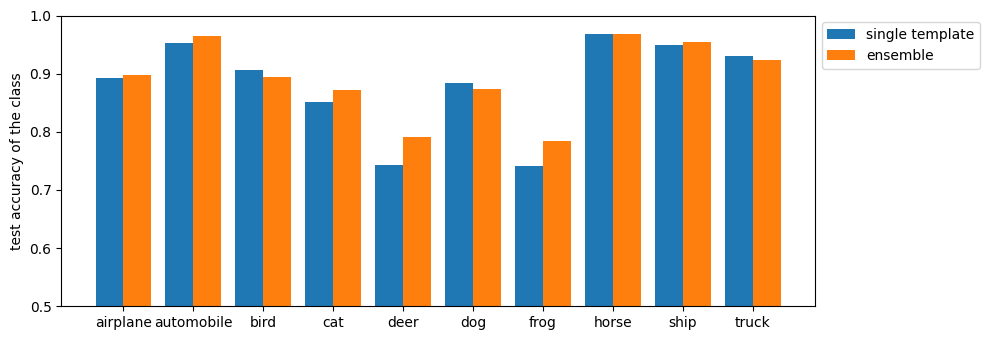

In [21]:
# Provided: zero-shot classification with three prompt sets.
TEMPLATES = ['a photo of a {}.', 'a blurry photo of a {}.', 'a low resolution photo of a {}.',
             'a photo of the small {}.', 'a photo of a big {}.', 'a bad photo of a {}.',
             'a close-up photo of a {}.', 'a pixelated photo of a {}.', 'a cropped photo of a {}.',
             'a bright photo of a {}.', 'a dark photo of a {}.', 'a jpeg corrupted photo of a {}.']
PROMPT_SETS = {'class name': ['{}'], 'single template': ['a photo of a {}.'], 'ensemble': TEMPLATES}

start = time.time()
test_clip_feats = encode_images(data['x_test'])
print(f'test images encoded in {time.time() - start:.0f}s')
zero_shot_rows, zero_shot_preds = [], {}
for prompt_set, templates in PROMPT_SETS.items():
    weights = build_text_classifier(CLASSES, templates)
    zero_shot_preds[prompt_set] = zero_shot_logits(test_clip_feats, weights).argmax(dim=1)
    acc = (zero_shot_preds[prompt_set] == data['y_test']).float().mean().item()
    zero_shot_rows.append({'prompts': prompt_set, 'num_templates': len(templates), 'test_acc': acc})
    print(f'{prompt_set:16s} ({len(templates):2d} templates): test accuracy {acc:.3f}')
save_table(zero_shot_rows, 'zero_shot')
text_weights = build_text_classifier(CLASSES, TEMPLATES)
zero_shot_acc = zero_shot_rows[-1]['test_acc']

fig, ax = plt.subplots(figsize=(10, 3.5))
for i, prompt_set in enumerate(['single template', 'ensemble']):
    per_class = [(zero_shot_preds[prompt_set][data['y_test'] == c] == c).float().mean().item() for c in range(10)]
    ax.bar(np.arange(10) + 0.4 * i - 0.2, per_class, width=0.4, color=f'C{i}', label=prompt_set)
ax.set_xticks(range(10))
ax.set_xticklabels(CLASSES)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel('test accuracy of the class')
ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
plt.show()


In [22]:
# Provided check: zero-shot accuracy.
accs = {r['prompts']: r['test_acc'] for r in zero_shot_rows}
assert min(accs.values()) >= 0.80
assert accs['ensemble'] >= accs['single template']
print('Zero-shot check passed')


Zero-shot check passed


#### Question 2.2: Few-Shot Adaptation [code] (8 points)

Adapt the zero-shot classifier with `k` labeled images per class, by training a
linear classifier on the frozen CLIP image embeddings. Compare a classifier
initialized randomly with one initialized from the zero-shot text weights.

**Lecture Connection**

> Small labeled target datasets  
> K-shot support sets with K labeled examples per class  
> Pretrained features as a useful starting point  
> *(Lec09 Transfer Learning and Adaptation, p. 38)*

> Linear probing trains a small head on frozen representations  
> *(Lec08 Pre-Training, p. 36)*

**Concept Connection**

The zero-shot classifier is itself a linear classifier with weights
`text_weights` and the scale `CLIP_SCALE`. A few-shot linear classifier on the
same embeddings can therefore start from random weights, so that all of its
knowledge about the classes comes from the `k` labeled images per class, or
from `text_weights`, so that the labeled images only correct the zero-shot
classifier. A randomly initialized classifier has to learn everything from the
labeled images and is trained with a learning rate of `1e-3`; a
text-initialized classifier should stay close to the zero-shot classifier and
is trained with a smaller learning rate of `1e-4`. All `k * C` training
embeddings fit into one batch, so every one of the 300 steps uses all of them.

**Implementation Guide and Point Breakdown**

The provided code creates the classifier (`nn.Linear` without bias) and an
AdamW optimizer without weight decay, and loops over `num_steps` steps.

- **`sample_few_shot` (2 points):** Use `torch.randperm(n, generator=...)` on
  the CPU.
- **Initialization (2 points):** Copy `text_weights` into the weight of the
  classifier, which has shape `(C, D)`.
- **Training step (4 points):** Log `step`, `loss`, and `train_acc` if a log is
  given.

| Tensor | Shape |
|---|---|
| `train_feats` | `(k * C, D)` |
| `classifier.weight` | `(C, D)` |
| `index` | `(k * C,)` |

**Expected Check:** `sample_few_shot` returns `k` distinct images of every class
and depends only on the seed; without training steps, the text-initialized
classifier predicts exactly like the zero-shot classifier and the random one
keeps its initialization; and training lowers the loss and logs the keys above.


In [23]:
def sample_few_shot(labels, k, seed, num_classes=10):
    """Indices of k random examples of every class."""
    ############################################################################
    # TODO 2.2 (2/8 points): With a torch.Generator seeded with seed, pick k   #
    # distinct random indices of every class (classes 0 to num_classes - 1, in #
    # order), and concatenate them into `index` on the device of labels.       #
    ############################################################################
    generator = torch.Generator().manual_seed(seed)
    labels_cpu = labels.cpu()
    selected_indices = []

    for class_id in range(num_classes):
        class_indices = torch.nonzero(
            labels_cpu == class_id,
            as_tuple=True,
        )[0]
        order = torch.randperm(
            len(class_indices),
            generator=generator,
        )
        selected_indices.append(class_indices[order[:k]])

    index = torch.cat(selected_indices).to(labels.device)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return index


def few_shot_classifier(train_feats, train_labels, text_weights=None, num_steps=300, lr=1e-3,
                        scale=CLIP_SCALE, log=None):
    """
    Train a linear classifier without bias on normalized CLIP embeddings. Its
    logits are scale * classifier(feats).

    Returns:
    - classifier: the trained nn.Linear
    """
    torch.manual_seed(SEED)
    num_classes = int(train_labels.max().item()) + 1 if text_weights is None else text_weights.shape[0]
    classifier = nn.Linear(train_feats.shape[1], num_classes, bias=False).to(train_feats.device)
    ############################################################################
    # TODO 2.2 (2/8 points): If text_weights is given, copy it into            #
    # classifier.weight without gradient tracking. Otherwise keep the default  #
    # random initialization.                                                   #
    ############################################################################
    if text_weights is not None:
        with torch.no_grad():
            classifier.weight.copy_(text_weights)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    optimizer = torch.optim.AdamW(classifier.parameters(), lr=lr, weight_decay=0.0)
    for step in range(num_steps):
        ########################################################################
        # TODO 2.2 (4/8 points): Compute the logits scale *                    #
        # classifier(train_feats) on all training features, the cross-entropy  #
        # loss, and update the classifier. If log is not None, log one row     #
        # with log.log_step using the keys step, loss, and train_acc.          #
        ########################################################################
        optimizer.zero_grad()

        logits = scale * classifier(train_feats)
        loss = F.cross_entropy(logits, train_labels)

        loss.backward()
        optimizer.step()

        if log is not None:
            with torch.no_grad():
                train_acc = (
                    (logits.argmax(dim=1) == train_labels)
                    .float()
                    .mean()
                    .item()
                )

            log.log_step(
                step=step,
                loss=loss.item(),
                train_acc=train_acc,
            )
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################
    if log is not None:
        log.save()
    return classifier


In [24]:
# Provided check: few-shot sampling and the few-shot classifier.
labels = data['y_train'][:2000]
index = sample_few_shot(labels, 4, seed=0)
assert index.shape == (40,) and len(set(index.tolist())) == 40
assert torch.equal(torch.bincount(labels[index], minlength=10), torch.full((10,), 4, device=device))
assert torch.equal(index, sample_few_shot(labels, 4, seed=0))
assert not torch.equal(index, sample_few_shot(labels, 4, seed=1))

feats = test_clip_feats[:200]
clf = few_shot_classifier(feats, data['y_test'][:200], text_weights, num_steps=0)
assert torch.equal(clf.weight, text_weights)
assert torch.equal(clf(feats).argmax(dim=1), zero_shot_logits(feats, text_weights).argmax(dim=1))
torch.manual_seed(SEED)
default = nn.Linear(512, 10, bias=False)
assert torch.equal(few_shot_classifier(feats, data['y_test'][:200], num_steps=0).weight.cpu(), default.weight)

check_log = TrainingLog('check_few_shot')
few_shot_classifier(feats[:40], data['y_test'][:40], num_steps=20, lr=1e-3, log=check_log)
reloaded = TrainingLog.load('check_few_shot')
assert set(reloaded.steps) == {'step', 'loss', 'train_acc'} and len(reloaded.steps['loss']) == 20
assert reloaded.steps['loss'][-1] < reloaded.steps['loss'][0]
print('sample_few_shot and few_shot_classifier check passed')


sample_few_shot and few_shot_classifier check passed


#### Provided: Few-Shot Accuracy

The cell below encodes the first 5,000 training images as the pool of labeled
images, and trains few-shot classifiers with 1, 2, 4, 8, 16, and 32 images per
class, three random samples each, with random initialization (learning rate
`1e-3`) and with text initialization (learning rate `1e-4`).
The plot shows the mean test accuracy and its range over the three samples,
together with the zero-shot accuracy of the ensemble, and the logs of one run
with 4 images per class. The results are saved to `logs/few_shot.csv`. You will
interpret Questions 2.1 and 2.2 in Question 2.3.

**Lecture Connection**

> Support examples from the target training partition  
> Separate query and held-out test examples  
> Repeated support-set sampling across trials  
> Mean performance and variability reporting  
> *(Lec09 Transfer Learning and Adaptation, p. 39)*

**Expected Check:** For every `k`, the text-initialized classifier is on
average more accurate than the randomly initialized one; and with 16 images per
class it is more accurate than the zero-shot classifier.


k= 1 random init: test accuracy 0.608 (0.601, 0.640, 0.582)
k= 1 text   init: test accuracy 0.887 (0.891, 0.896, 0.874)
k= 2 random init: test accuracy 0.713 (0.678, 0.741, 0.718)
k= 2 text   init: test accuracy 0.885 (0.880, 0.883, 0.892)
k= 4 random init: test accuracy 0.807 (0.808, 0.800, 0.812)
k= 4 text   init: test accuracy 0.898 (0.903, 0.895, 0.897)
k= 8 random init: test accuracy 0.861 (0.846, 0.874, 0.863)
k= 8 text   init: test accuracy 0.907 (0.900, 0.918, 0.904)
k=16 random init: test accuracy 0.887 (0.883, 0.892, 0.886)
k=16 text   init: test accuracy 0.915 (0.909, 0.922, 0.913)
k=32 random init: test accuracy 0.899 (0.896, 0.904, 0.897)
k=32 text   init: test accuracy 0.918 (0.914, 0.922, 0.916)


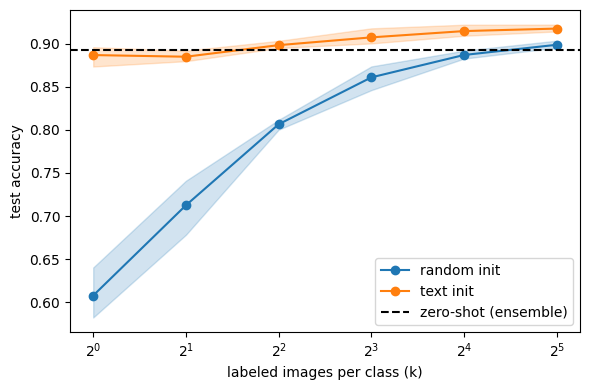

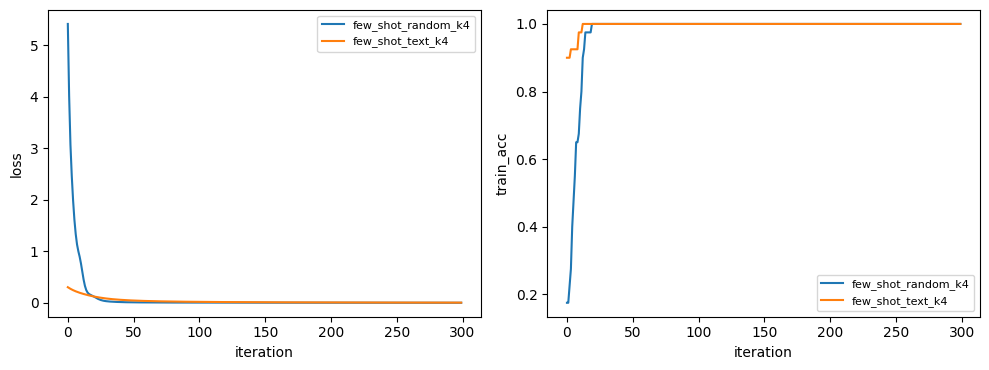

In [25]:
# Provided: few-shot classifiers with random and text initialization.
pool_feats, pool_labels = encode_images(data['x_train'][:5000]), data['y_train'][:5000]
K_VALUES = [1, 2, 4, 8, 16, 32]
few_shot_rows, few_shot_logs = [], []
for k in K_VALUES:
    for init in ['random', 'text']:
        accs = []
        for seed in range(3):
            idx = sample_few_shot(pool_labels, k, seed)
            log = TrainingLog(f'few_shot_{init}_k{k}') if (k == 4 and seed == 0) else None
            clf = few_shot_classifier(pool_feats[idx], pool_labels[idx],
                                      text_weights if init == 'text' else None,
                                      lr=1e-3 if init == 'random' else 1e-4, log=log)
            with torch.no_grad():
                accs.append((clf(test_clip_feats).argmax(dim=1) == data['y_test']).float().mean().item())
            if log is not None:
                few_shot_logs.append(log)
        few_shot_rows.append({'k': k, 'init': init, 'mean_test_acc': float(np.mean(accs)),
                              'min_test_acc': min(accs), 'max_test_acc': max(accs)})
        print(f'k={k:2d} {init:6s} init: test accuracy {np.mean(accs):.3f} '
              f'({", ".join(f"{a:.3f}" for a in accs)})')
save_table(few_shot_rows, 'few_shot')

fig, ax = plt.subplots(figsize=(6, 4))
for i, init in enumerate(['random', 'text']):
    rows = [r for r in few_shot_rows if r['init'] == init]
    ax.plot(K_VALUES, [r['mean_test_acc'] for r in rows], 'o-', color=f'C{i}', label=f'{init} init')
    ax.fill_between(K_VALUES, [r['min_test_acc'] for r in rows], [r['max_test_acc'] for r in rows],
                    color=f'C{i}', alpha=0.2)
ax.axhline(zero_shot_acc, color='k', ls='--', label='zero-shot (ensemble)')
ax.set_xscale('log', base=2)
ax.set_xlabel('labeled images per class (k)')
ax.set_ylabel('test accuracy')
ax.legend()
fig.tight_layout()
plt.show()
plot_logs(few_shot_logs, step_keys=['loss', 'train_acc'], smooth=1)
plt.show()


In [26]:
# Provided check: text initialization helps.
mean_acc = {(r['k'], r['init']): r['mean_test_acc'] for r in few_shot_rows}
for k in K_VALUES:
    assert mean_acc[(k, 'text')] > mean_acc[(k, 'random')], k
assert mean_acc[(16, 'text')] > zero_shot_acc
print('Few-shot check passed')


Few-shot check passed


#### Question 2.3: Zero-Shot versus Few-Shot [written] (5 points)

---

Answer using the zero-shot results and the few-shot plot:

1. Compare the three prompt sets. Why does the wording of the prompt change the
   accuracy, although the images and the encoders are the same? (2 points)
2. How many labeled images per class does the randomly initialized classifier
   need to match the zero-shot classifier? Explain why the text initialization
   helps most when `k` is small, and why it can still fall slightly below the
   zero-shot accuracy with `k = 1`. (3 points)

$\color{blue}{\textit Your Answer:}$

<!-- ANSWER_START: 2.3 -->
1. 클래스 이름, 단일 템플릿, ensemble의 정확도는 각각 87.3%, 88.2%, 89.2%였다. 문구가 바뀌면 텍스트 임베딩과 이미지의 유사도가 달라지므로 동일한 이미지와 encoder에서도 예측이 달라진다. 이미지·문장 쌍으로 학습한 CLIP에는 문장 형태의 설명이 도움이 될 수 있으며, ensemble은 여러 표현을 결합해 특정 문구에 대한 의존도를 줄였다.

2. 무작위 초기화는 클래스당 16개에서 평균 88.7%, 32개에서 89.9%였으므로, 실험한 조건 중 zero-shot의 89.2%를 처음 넘어선 것은 32개였다. 텍스트 초기화는 유용한 클래스 가중치에서 출발하므로 데이터가 적을수록 이점이 크다. 다만 k=1에서는 한 이미지가 전체 클래스를 충분히 대표하지 못해 그 표본에 과적합할 수 있으며, 실제 정확도도 88.7%로 zero-shot보다 0.5%p 낮았다.


<!-- ANSWER_END: 2.3 -->

---


### Section 4: Parameter-Efficient Fine-Tuning and Forgetting


#### Question 2.4: Low-Rank Adaptation (LoRA) [code] (10 points)

Implement a LoRA layer that adds a trainable low-rank update to a frozen linear
layer. The provided `add_lora` attaches it to the query and value projections
of every Transformer layer of the CLIP image encoder.

**Lecture Connection**

> Large trainable parameter counts in full fine-tuning  
> Additional memory for gradients and optimizer states  
> Small trainable parameter sets in PEFT  
> *(Lec09 Transfer Learning and Adaptation, p. 25)*

> Frozen pretrained matrix W0  
> Trainable low-rank factors A and B  
> Rank r as the adaptation-capacity parameter  
> Optional merging of trained updates into the base weights  
> *(Lec09 Transfer Learning and Adaptation, p. 29)*

> Lower trainable parameter counts for small ranks  
> Matrix-specific savings rather than whole-model savings  
> *(Lec09 Transfer Learning and Adaptation, p. 30)*

> Query and value projections as common examples  
> Frozen original projection weights  
> *(Lec09 Transfer Learning and Adaptation, p. 31)*

**Concept Connection**

A frozen pretrained linear layer computes $y = W_0 x + b$ with
$W_0 \in \mathbb{R}^{d_\text{out} \times d_\text{in}}$. LoRA keeps $W_0$
and $b$ fixed and learns a low-rank update
$\Delta W = \frac{\alpha}{r} B A$ with
$A \in \mathbb{R}^{r \times d_\text{in}}$ and
$B \in \mathbb{R}^{d_\text{out} \times r}$:

$$
y = W_0 x + b + \frac{\alpha}{r} B A x .
$$

Only $A$ and $B$ are trained, $r(d_\text{in} + d_\text{out})$ parameters
instead of $d_\text{out} d_\text{in}$. $B$ starts at zero, so the adapted layer
initially computes exactly the pretrained function, while $A$ starts random
(Kaiming uniform, as in the `peft` library). Because $\Delta W$ is a matrix of
the same shape as $W_0$, it can be merged after training, $W = W_0 + \Delta W$,
so that the adapted model is as fast as the original one. The image encoder of
CLIP ViT-B/32 has 12 Transformer layers, and the self-attention of each has four
$768 \times 768$ projections: `q_proj`, `k_proj`, `v_proj`, and `out_proj`.

**Implementation Guide and Point Breakdown**

- **`LoRALinear.__init__` (4 points):** Freeze every parameter of `base`. Create
  `self.A` with `nn.init.kaiming_uniform_(..., a=math.sqrt(5))` and `self.B`
  with zeros, as `nn.Parameter`s on the device of `base.weight`.
- **`LoRALinear.forward` (3 points):** Compute the low-rank term as
  `(x @ A.T) @ B.T`, without forming $\Delta W$; `x` can have any number of
  leading dimensions.
- **`LoRALinear.merged_weight` (3 points):** Return $W_0 + \frac{\alpha}{r} B A$.

| Tensor | Shape |
|---|---|
| `x`, output | `(N, T, d_in)`, `(N, T, d_out)` (CLIP: `T = 50` tokens, `d_in = d_out = 768`) |
| `self.A`, `self.B` | `(r, d_in)`, `(d_out, r)` |
| `merged_weight()` | `(d_out, d_in)` |

**Expected Check:** Only `A` and `B` are trainable, and with `r = 8` on a
`768 x 768` projection they have 12,288 parameters, 2.08% of a full update; the
layer initially computes the same output as the frozen layer; with a nonzero
`B` its output equals one linear layer with `merged_weight()`; gradients reach
`A` and `B` but not the frozen weight; and `add_lora` makes 294,912 parameters
of the CLIP image encoder trainable without changing its output.


In [27]:
class LoRALinear(nn.Module):
    """A frozen nn.Linear plus a trainable low-rank update (alpha / rank) * B A."""

    def __init__(self, base, rank=8, alpha=16):
        super().__init__()
        self.base = base
        self.rank = rank
        self.scale = alpha / rank
        ########################################################################
        # TODO 2.4 (4/10 points): Freeze every parameter of base. Create       #
        # self.A of shape (rank, in_features), initialized with                #
        # nn.init.kaiming_uniform_(..., a=math.sqrt(5)), and self.B of shape   #
        # (out_features, rank), initialized with zeros, both as nn.Parameter   #
        # on the device and with the dtype of base.weight.                     #
        ########################################################################
        for parameter in self.base.parameters():
            parameter.requires_grad_(False)

        self.A = nn.Parameter(
            torch.empty(
                rank,
                base.in_features,
                device=base.weight.device,
                dtype=base.weight.dtype,
            )
        )
        self.B = nn.Parameter(
            torch.zeros(
                base.out_features,
                rank,
                device=base.weight.device,
                dtype=base.weight.dtype,
            )
        )

        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

    def forward(self, x):
        ########################################################################
        # TODO 2.4 (3/10 points): Compute `out`: the output of the frozen base #
        # layer plus self.scale times the low-rank term (x A^T) B^T, without   #
        # forming the full update matrix.                                      #
        ########################################################################
        low_rank_output = (x @ self.A.T) @ self.B.T
        out = self.base(x) + self.scale * low_rank_output
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################
        return out

    def merged_weight(self):
        """Weight of a single nn.Linear that computes the same function: W0 + (alpha / rank) * B A."""
        ########################################################################
        # TODO 2.4 (3/10 points): Compute `weight` = W0 + self.scale * B A,    #
        # where W0 is the weight of the frozen base layer.                     #
        ########################################################################
        weight = self.base.weight + self.scale * (self.B @ self.A)
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################
        return weight


def add_lora(vision_model, rank=8, alpha=16, targets=('q_proj', 'v_proj')):
    """Provided: replace the target projections of every Transformer layer by LoRALinear layers."""
    for layer in vision_model.encoder.layers:
        for target in targets:
            setattr(layer.self_attn, target, LoRALinear(getattr(layer.self_attn, target), rank, alpha))
    return vision_model


In [28]:
# Provided check: LoRALinear and add_lora.
torch.manual_seed(SEED)
base = nn.Linear(768, 768).to(device)
lora = LoRALinear(base, rank=8, alpha=16)
trainable = {name: p.numel() for name, p in lora.named_parameters() if p.requires_grad}
print('trainable parameters:', trainable)
assert set(trainable) == {'A', 'B'} and sum(trainable.values()) == 8 * (768 + 768) == 12288
print(f'LoRA: {12288:,d} parameters = {12288 / (768 * 768):.2%} of a full 768 x 768 update ({768 * 768:,d})')
assert lora.A.shape == (8, 768) and lora.B.shape == (768, 8) and torch.all(lora.B == 0)
x = torch.randn(4, 50, 768, device=device)
with torch.no_grad():
    assert torch.allclose(lora(x), base(x)), 'with B = 0 the output must equal the frozen layer'
    lora.B.normal_()
    assert lora(x).shape == (4, 50, 768)
    assert lora.merged_weight().shape == (768, 768)
    assert torch.allclose(lora(x), F.linear(x, lora.merged_weight(), base.bias), rtol=1e-4, atol=1e-3)
lora(x).square().mean().backward()
assert base.weight.grad is None and lora.A.grad is not None and lora.B.grad is not None

vision = add_lora(copy.deepcopy(clip_model.vision_model))
num_trainable = sum(p.numel() for p in vision.parameters() if p.requires_grad)
print(f'trainable parameters of the CLIP image encoder with LoRA: {num_trainable:,d}')
assert num_trainable == 12 * 2 * 12288
pixels = clip_preprocess(data['x_val'][:4])
with torch.no_grad():
    assert torch.allclose(vision(pixel_values=pixels).pooler_output,
                          clip_model.vision_model(pixel_values=pixels).pooler_output, atol=1e-4)
del base, lora, vision
print('LoRALinear and add_lora check passed')


trainable parameters: {'A': 6144, 'B': 6144}
LoRA: 12,288 parameters = 2.08% of a full 768 x 768 update (589,824)
trainable parameters of the CLIP image encoder with LoRA: 294,912
LoRALinear and add_lora check passed


#### Provided: Linear Probing, LoRA, and Full Fine-Tuning of CLIP

The cell below adapts copies of CLIP to CIFAR-10 with 100 labeled images per
class in three ways. Every method starts from the zero-shot classifier
(`text_weights`) as its head, trained with a learning rate of `1e-4`, and is
trained for 3 epochs with random crops and flips.

| Method | Trainable parameters | Encoder learning rate |
|---|---|---|
| `linear` | the head | — |
| `lora` | LoRA (`r = 8`, `alpha = 16`) on `q_proj` and `v_proj`, and the head | `5e-4` |
| `full` | the whole image encoder and the head | `1e-5` |

Besides the loss and the validation accuracy, the log records after every
epoch the **CIFAR-100 zero-shot accuracy** of the adapted image encoder with the
original text encoder (on 2,000 CIFAR-100 test images). CIFAR-100 has 100
classes that are not part of the target task, and CLIP recognizes them before
adaptation, so this accuracy measures a capability that the model had before:
a drop indicates catastrophic forgetting. The table also reports the trainable
parameters, the peak GPU memory of each run, and the CIFAR-100 zero-shot
accuracy on all 10,000 test images. The results are saved to
`logs/peft_comparison.csv`, and you will interpret them in Question 2.5.

**Lecture Connection**

> Reduced optimizer-state and trainable-gradient storage  
> Continued forward computation through frozen components  
> *(Lec09 Transfer Learning and Adaptation, p. 26)*

> Decreased performance on earlier tasks  
> Source-task evaluation before and after adaptation  
> *(Lec09 Transfer Learning and Adaptation, p. 21)*

> Smaller encoder learning rates  
> Joint monitoring of target and retained capabilities  
> *(Lec09 Transfer Learning and Adaptation, p. 22)*

**Expected Check:** `lora` trains less than 1% of the parameters of `full` and is
at least `0.01` more accurate on the CIFAR-10 test set than `linear`; `linear`
leaves the CIFAR-100 zero-shot accuracy unchanged; and after adaptation the
CIFAR-100 zero-shot accuracy of `lora` is at least `0.03` higher than that of
`full`.


CIFAR-100 zero-shot accuracy of CLIP before adaptation: 0.645
[clip_linear_100] epoch 1: loss 0.513, val acc 0.919, CIFAR-100 zero-shot 0.648
[clip_linear_100] epoch 2: loss 0.438, val acc 0.920, CIFAR-100 zero-shot 0.648
[clip_linear_100] epoch 3: loss 0.384, val acc 0.923, CIFAR-100 zero-shot 0.648
linear trainable       5,120 | CIFAR-10 test 0.919 | CIFAR-100 zero-shot 0.645 -> 0.645 | peak memory 3.5 GB | 114s
[clip_lora_100] epoch 1: loss 0.211, val acc 0.944, CIFAR-100 zero-shot 0.695
[clip_lora_100] epoch 2: loss 0.121, val acc 0.956, CIFAR-100 zero-shot 0.710
[clip_lora_100] epoch 3: loss 0.203, val acc 0.959, CIFAR-100 zero-shot 0.711
lora   trainable     300,032 | CIFAR-10 test 0.949 | CIFAR-100 zero-shot 0.645 -> 0.711 | peak memory 4.2 GB | 128s
[clip_full_100] epoch 1: loss 0.585, val acc 0.892, CIFAR-100 zero-shot 0.547
[clip_full_100] epoch 2: loss 0.348, val acc 0.942, CIFAR-100 zero-shot 0.612
[clip_full_100] epoch 3: loss 0.107, val acc 0.925, CIFAR-100 zero-shot 0.60

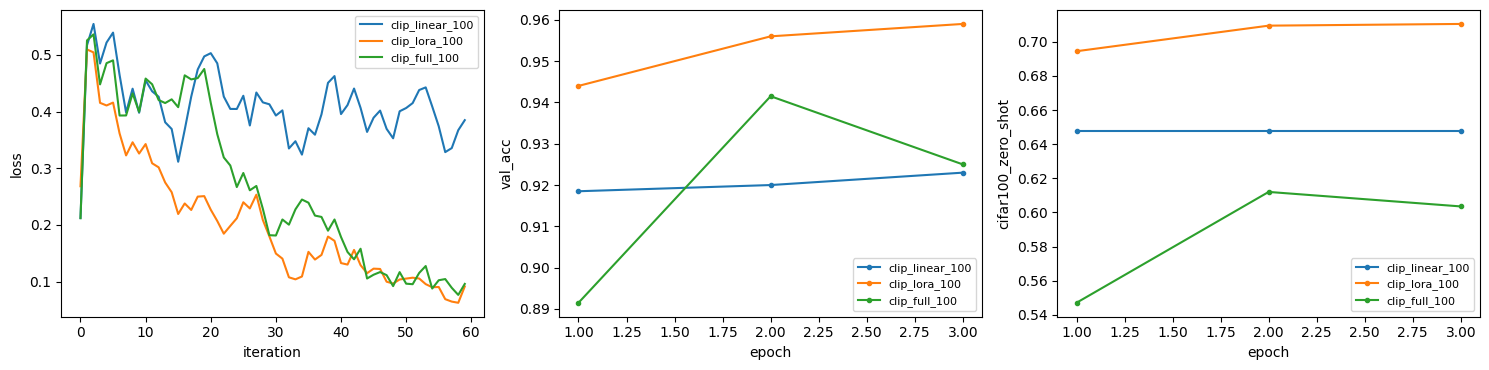

In [29]:
# Provided: adapt CLIP with linear probing, LoRA, and full fine-tuning.
cifar100 = CIFAR100('datasets', train=False, download=True)
c100_x = torch.from_numpy(cifar100.data).permute(0, 3, 1, 2).float().div(255).to(device)
c100_y = torch.tensor(cifar100.targets, device=device)
c100_weights = build_text_classifier([name.replace('_', ' ') for name in cifar100.classes], TEMPLATES)
cifar100_zero_shot_before = (zero_shot_logits(encode_images(c100_x), c100_weights).argmax(dim=1)
                             == c100_y).float().mean().item()
print(f'CIFAR-100 zero-shot accuracy of CLIP before adaptation: {cifar100_zero_shot_before:.3f}')


def clip_embed_with(model, x, batch_size=250):
    """Provided: normalized image embeddings from the image encoder of model (with gradients if enabled)."""
    embeds = []
    for start in range(0, len(x), batch_size):
        pixels = clip_preprocess(x[start:start + batch_size])
        embeds.append(model.visual_projection(model.vision_model(pixel_values=pixels).pooler_output))
    return F.normalize(torch.cat(embeds), dim=1)


def adapt_clip(method, name, per_class=100, num_epochs=3, batch_size=50, encoder_lr=None):
    """Provided: adapt a copy of CLIP to CIFAR-10 with method in ('linear', 'lora', 'full')."""
    torch.manual_seed(SEED)
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    model = copy.deepcopy(clip_model)
    if method == 'lora':
        add_lora(model.vision_model)
    elif method == 'full':
        for p in list(model.vision_model.parameters()) + list(model.visual_projection.parameters()):
            p.requires_grad = True
    head = nn.Linear(512, 10, bias=False).to(device)
    with torch.no_grad():
        head.weight.copy_(text_weights)
    encoder_params = [p for p in model.parameters() if p.requires_grad]
    groups = [{'params': list(head.parameters()), 'lr': 1e-4}]
    if encoder_params:
        groups.append({'params': encoder_params, 'lr': encoder_lr})
    optimizer = torch.optim.AdamW(groups, weight_decay=0.0)
    idx = balanced_subset(data['y_train'], per_class)
    loader = TensorLoader(data['x_train'][idx], data['y_train'][idx], batch_size, shuffle=True)
    log = TrainingLog(name)
    step = 0
    for epoch in range(1, num_epochs + 1):
        model.train()
        for x, y in loader:
            loss = F.cross_entropy(CLIP_SCALE * head(clip_embed_with(model, random_crop_flip(x))), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            log.log_step(step=step, loss=loss.item())
            step += 1
        model.eval()
        with torch.no_grad():
            val_acc = (head(clip_embed_with(model, data['x_val'][:2000])).argmax(dim=1)
                       == data['y_val'][:2000]).float().mean().item()
            c100_acc = (zero_shot_logits(clip_embed_with(model, c100_x[:2000]), c100_weights).argmax(dim=1)
                        == c100_y[:2000]).float().mean().item()
        log.log_epoch(epoch=epoch, val_acc=val_acc, cifar100_zero_shot=c100_acc)
        print(f'[{name}] epoch {epoch}: loss {loss.item():.3f}, val acc {val_acc:.3f}, '
              f'CIFAR-100 zero-shot {c100_acc:.3f}')
    with torch.no_grad():
        test_acc = (head(clip_embed_with(model, data['x_test'])).argmax(dim=1) == data['y_test']).float().mean().item()
        c100_after = (zero_shot_logits(clip_embed_with(model, c100_x), c100_weights).argmax(dim=1)
                      == c100_y).float().mean().item()
    result = {'method': method,
              'trainable_params': sum(p.numel() for p in encoder_params) + head.weight.numel(),
              'test_acc': test_acc,
              'cifar100_zero_shot_before': cifar100_zero_shot_before,
              'cifar100_zero_shot_after': c100_after,
              'peak_memory_gb': torch.cuda.max_memory_allocated() / 2 ** 30 if device.type == 'cuda' else float('nan')}
    log.save()
    del model, optimizer
    return log, result


peft_logs, peft_rows = [], []
for method, encoder_lr in [('linear', None), ('lora', 5e-4), ('full', 1e-5)]:
    start = time.time()
    log, result = adapt_clip(method, f'clip_{method}_100', encoder_lr=encoder_lr)
    peft_logs.append(log)
    peft_rows.append(result)
    print(f"{method:6s} trainable {result['trainable_params']:>11,d} | CIFAR-10 test {result['test_acc']:.3f} | "
          f"CIFAR-100 zero-shot {result['cifar100_zero_shot_before']:.3f} -> "
          f"{result['cifar100_zero_shot_after']:.3f} | peak memory {result['peak_memory_gb']:.1f} GB | "
          f"{time.time() - start:.0f}s")
save_table(peft_rows, 'peft_comparison')
plot_logs(peft_logs, step_keys=['loss'], epoch_keys=['val_acc', 'cifar100_zero_shot'], smooth=5)
plt.show()


In [30]:
# Provided check: parameter efficiency and forgetting.
rows = {r['method']: r for r in peft_rows}
assert rows['lora']['trainable_params'] < 0.01 * rows['full']['trainable_params']
assert rows['lora']['test_acc'] >= rows['linear']['test_acc'] + 0.01
assert abs(rows['linear']['cifar100_zero_shot_after'] - cifar100_zero_shot_before) < 0.005
assert rows['lora']['cifar100_zero_shot_after'] >= rows['full']['cifar100_zero_shot_after'] + 0.03
print('PEFT and forgetting check passed')


PEFT and forgetting check passed


#### Question 2.5: Parameter-Efficient Fine-Tuning and Forgetting [written] (6 points)

---

Answer using the LoRA check, the comparison table, and the logs:

1. Compare the trainable parameters, the peak GPU memory, and the CIFAR-10 test
   accuracy of `linear`, `lora`, and `full`. For one `768 x 768` projection,
   compute the trainable parameters of a full update, of LoRA with `r = 8`, and
   of a bottleneck adapter with `d = 768` and `r = 8` (a down-projection and an
   up-projection, each with a bias). Why can such a small update adapt the
   model well? (3 points)
2. Which method shows catastrophic forgetting in the CIFAR-100 zero-shot
   accuracy, and why do `linear` and `lora` not? Distinguish catastrophic
   forgetting from negative transfer, and state which of the two the MNIST
   results of Part 1 (`linear` versus `scratch` with 50 images per class) show.
   (3 points)

$\color{blue}{\textit Your Answer:}$

<!-- ANSWER_START: 2.5 -->
1. linear, LoRA, full의 학습 파라미터 수는 각각 5,120개, 300,032개, 87,854,336개이고, 최대 GPU 메모리는 3.5, 4.2, 5.6 GB였다. CIFAR-10 정확도는 각각 91.9%, 94.9%, 91.6%로 LoRA가 가장 높았다.
768×768 가중치의 전체 갱신에는 589,824개, rank 8 LoRA에는 8×768+768×8=12,288개가 필요하다. Bias를 포함한 bottleneck adapter는 (768×8+8)+(8×768+768)=13,064개이다. 사전학습 특징이 이미 유용하므로 작은 저랭크 갱신만으로도 목표 과제에 효과적으로 적응할 수 있다.

2. full은 CIFAR-100 정확도가 64.5%에서 60.3%로 하락하여 기존 능력의 망각을 보였다. linear는 encoder를 변경하지 않아 64.5%를 유지했다. LoRA는 기존 가중치를 고정하고 제한된 갱신만 학습했으며, 이번 실험에서는 71.1%로 향상되어 망각이 관찰되지 않았다. 다만 LoRA가 항상 망각을 방지하는 것은 아니다.
Catastrophic forgetting은 새 과제 학습 후 기존 능력이 저하되는 현상이고, negative transfer는 전이가 목표 과제 성능에 불리하게 작용하는 현상이다. MNIST 클래스당 50개에서 linear의 82.0%가 scratch의 95.9%보다 낮았던 결과는 해당 전이 전략의 negative transfer를 보여준다.

<!-- ANSWER_END: 2.5 -->

---


### Section 5: Distribution Shift


#### Question 2.6: Distribution Shift and Batch Normalization [code] (8 points)

Implement two image corruptions that change the test distribution, and adapt
the batch normalization statistics of a trained model to unlabeled images from
the new distribution.

**Lecture Connection**

> Source distribution as the original learning environment  
> Target distribution as the application environment  
> Possible performance degradation on unfamiliar target data  
> *(Lec09 Transfer Learning and Adaptation, p. 34)*

> Target-domain data available during adaptation  
> Unsupervised adaptation with unlabeled target examples  
> *(Lec09 Transfer Learning and Adaptation, p. 35)*

> Running statistics are used during inference  
> *(Lec03 Convolutional Neural Networks, p. 26)*

**Concept Connection**

A model is trained on one distribution (the source) and often deployed on a
different one (the target): images taken with another camera, in fog, or with
noise. The corruptions in this section follow the idea of CIFAR-10-C (Hendrycks
and Dietterich, 2019). Even if the classes are the same, such a **distribution
shift** changes the statistics of the activations inside the network, while
every batch normalization layer still normalizes with the running mean and
variance of the source data. Re-estimating these statistics on unlabeled target
images, while keeping all weights fixed, is a simple form of **test-time
adaptation** (AdaBN; Li et al., 2016; Schneider et al., 2020). With `momentum =
None`, `nn.BatchNorm2d` replaces the exponential moving average by the plain
average over all batches it sees.

For the blur, the 1D Gaussian kernel with radius $r$ and standard deviation
$\sigma$ is

$$
k_j = \frac{\exp(-j^2 / 2\sigma^2)}{\sum_{i=-r}^{r} \exp(-i^2 / 2\sigma^2)},\qquad j = -r, \dots, r .
$$

Blurring along the width and then along the height with $k$ is the same as one
2D convolution with the outer product $k k^\top$.

**Implementation Guide and Point Breakdown**

- **`gaussian_blur` (3 points):** A depthwise convolution uses a weight of
  shape `(channels, 1, 1, 2r + 1)` (width) or `(channels, 1, 2r + 1, 1)`
  (height) and `groups=channels`.
- **`low_contrast` (1 point):** One mean per image.
- **`adapt_batchnorm` (4 points):** `module.reset_running_stats()` resets the
  statistics. The original model must not change.

| Tensor | Shape |
|---|---|
| `x`, outputs of the corruptions | `(N, 3, 32, 32)` |
| width and height kernels | `(3, 1, 1, 2r + 1)`, `(3, 1, 2r + 1, 1)` |
| per-image mean in `low_contrast` | `(N, 1, 1, 1)` |

**Expected Check:** The blur leaves a constant image unchanged and matches a 2D
convolution with the outer-product kernel; `low_contrast` keeps the mean of an
image and scales its standard deviation by `factor`; and `adapt_batchnorm`
leaves the original model and all weights unchanged, returns a model in
evaluation mode, and sets the running mean of the first batch normalization
layer to the mean of its inputs over all unlabeled images.


In [31]:
def gaussian_noise(x, std=0.08, seed=SEED):
    """Provided: add Gaussian noise with a fixed seed and clamp to [0, 1]."""
    generator = torch.Generator(device=x.device).manual_seed(seed)
    return (x + std * torch.randn(x.shape, generator=generator, device=x.device)).clamp(0, 1)


def gaussian_blur(x, sigma=1.0, radius=2):
    """Blur every channel of x with a separable Gaussian kernel."""
    ############################################################################
    # TODO 2.6 (3/8 points): Build the normalized 1D Gaussian kernel with      #
    # offsets -radius to radius, and blur every channel separately: first      #
    # along the width, then along the height, each time padding by radius with #
    # reflect padding and applying F.conv2d with groups equal to the number of #
    # channels.                                                                #
    ############################################################################
    channels = x.shape[1]
    offsets = torch.arange(
        -radius,
        radius + 1,
        device=x.device,
        dtype=x.dtype,
    )
    kernel = torch.exp(-(offsets ** 2) / (2 * sigma ** 2))
    kernel = kernel / kernel.sum()

    width_kernel = kernel.view(1, 1, 1, -1).repeat(
        channels, 1, 1, 1
    )
    height_kernel = kernel.view(1, 1, -1, 1).repeat(
        channels, 1, 1, 1
    )

    x_blur = F.conv2d(
        F.pad(x, (radius, radius, 0, 0), mode='reflect'),
        width_kernel,
        groups=channels,
    )
    x_blur = F.conv2d(
        F.pad(x_blur, (0, 0, radius, radius), mode='reflect'),
        height_kernel,
        groups=channels,
    )
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return x_blur


def low_contrast(x, factor=0.3):
    """Reduce the contrast of every image by factor."""
    ############################################################################
    # TODO 2.6 (1/8 points): Move every pixel toward the mean of its image,    #
    # over all channels and positions: mean + factor * (x - mean). Clamp to    #
    # [0, 1].                                                                  #
    ############################################################################
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x_low = (mean + factor * (x - mean)).clamp(0, 1)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return x_low


def adapt_batchnorm(model, x_unlabeled, batch_size=200):
    """
    Return a copy of model whose batch normalization layers use statistics
    estimated on x_unlabeled. No labels are used, and no weight changes.
    """
    ############################################################################
    # TODO 2.6 (4/8 points): Copy the model with copy.deepcopy. In the copy,   #
    # reset the running statistics of every nn.BatchNorm2d layer and set its   #
    # momentum to None. Put the copy in training mode and, without gradient    #
    # tracking, pass x_unlabeled through it in chunks of batch_size. Finally   #
    # put the copy in evaluation mode and store it in `adapted`.               #
    ############################################################################
    adapted = copy.deepcopy(model)

    for module in adapted.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.reset_running_stats()
            module.momentum = None

    adapted.train()

    with torch.no_grad():
        for start in range(0, len(x_unlabeled), batch_size):
            adapted(x_unlabeled[start:start + batch_size])

    adapted.eval()
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return adapted


In [32]:
# Provided check: corruptions and batch normalization adaptation.
x = data['x_val'][:16]
assert gaussian_blur(x).shape == x.shape
constant = torch.full((2, 3, 32, 32), 0.3, device=device)
assert torch.allclose(gaussian_blur(constant, sigma=1.5), constant, atol=1e-6)
k = torch.exp(-torch.arange(-2, 3, device=device).float() ** 2 / 2)
k = k / k.sum()
expected = F.conv2d(F.pad(x, (2, 2, 2, 2), mode='reflect'), torch.outer(k, k).expand(3, 1, 5, 5), groups=3)
print('blur error:', (gaussian_blur(x, sigma=1.0) - expected).abs().max().item())
assert (gaussian_blur(x, sigma=1.0) - expected).abs().max() < 1e-5
assert (gaussian_blur(x, sigma=0.1) - x).abs().max() < 1e-4

mid = 0.4 + 0.2 * x   # values in [0.4, 0.6], so that nothing is clamped
low = low_contrast(mid, 0.3)
assert torch.allclose(low.mean(dim=(1, 2, 3)), mid.mean(dim=(1, 2, 3)), atol=1e-5)
assert torch.allclose(low.std(dim=(1, 2, 3)), 0.3 * mid.std(dim=(1, 2, 3)), atol=1e-5)
assert low_contrast(x).min() >= 0 and low_contrast(x).max() <= 1

torch.manual_seed(SEED)
model = TransferResNet(pretrained=True).to(device).eval()
state_before = copy.deepcopy(model.state_dict())
x_unlabeled = low_contrast(data['x_val'][:400])
adapted = adapt_batchnorm(model, x_unlabeled, batch_size=100)
assert all(torch.equal(v, model.state_dict()[k]) for k, v in state_before.items()), 'model must not change'
assert not adapted.training and adapted is not model
assert all(torch.equal(p, q) for p, q in zip(model.parameters(), adapted.parameters()))
with torch.no_grad():
    stem = adapted.backbone.conv1(adapted.prepare(x_unlabeled))
print('running mean error:', (adapted.backbone.bn1.running_mean - stem.mean(dim=(0, 2, 3))).abs().max().item())
assert torch.allclose(adapted.backbone.bn1.running_mean, stem.mean(dim=(0, 2, 3)), rtol=1e-2, atol=1e-3)
assert not torch.allclose(adapted.backbone.bn1.running_mean, model.backbone.bn1.running_mean)
del model, adapted
print('Corruption and adapt_batchnorm check passed')


blur error: 2.384185791015625e-07
running mean error: 5.960464477539063e-08
Corruption and adapt_batchnorm check passed


#### Provided: Accuracy under Distribution Shift

The cell below corrupts all test images with noise, blur, and low contrast, and
evaluates the ResNet-18 fine-tuned in Part 1 (`full_low_lr` with 500 images per
class) without adaptation and after re-estimating its batch normalization
statistics on the first 16, 64, 256, or 1,000 corrupted test images (without
their labels). It also evaluates the zero-shot CLIP classifier, which was not
trained on CIFAR-10 at all, and a model adapted to noisy images that is then
evaluated on clean images. The last plot compares, for every channel of the
first batch normalization layer `backbone.bn1`, the running standard deviation
of the source model with the one re-estimated on 1,000 images of each
corruption. The results are saved to `logs/distribution_shift.csv`.

**Lecture Connection**

> Target-domain evaluation as a generalization requirement  
> *(Lec09 Transfer Learning and Adaptation, p. 34)*

> Feature alignment between source and target embeddings  
> *(Lec09 Transfer Learning and Adaptation, p. 36)*

**Expected Check:** Every corruption lowers the accuracy of the ResNet-18 by at
least `0.15`; adapting to 1,000 unlabeled images recovers at least `0.08` of it
for every corruption; adapting to clean images changes the clean accuracy by
less than `0.02`; and statistics adapted to noise lower the clean accuracy by
more than `0.2`.


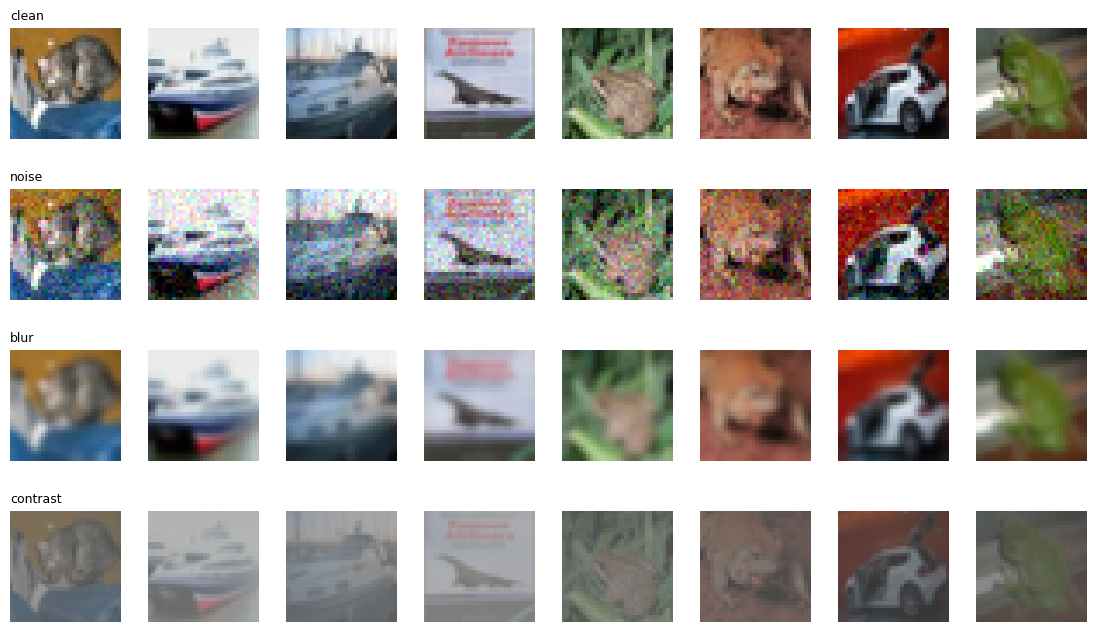

clean    : ResNet-18 0.827 | adapted n=16: 0.727 n=64: 0.798 n=256: 0.820 n=1000: 0.825 | CLIP zero-shot 0.892
noise    : ResNet-18 0.533 | adapted n=16: 0.660 n=64: 0.716 n=256: 0.717 n=1000: 0.727 | CLIP zero-shot 0.488
blur     : ResNet-18 0.587 | adapted n=16: 0.675 n=64: 0.709 n=256: 0.740 n=1000: 0.743 | CLIP zero-shot 0.660
contrast : ResNet-18 0.526 | adapted n=16: 0.695 n=64: 0.766 n=256: 0.801 n=1000: 0.802 | CLIP zero-shot 0.787
statistics adapted to noise, evaluated on clean images: 0.477 (source model 0.827)


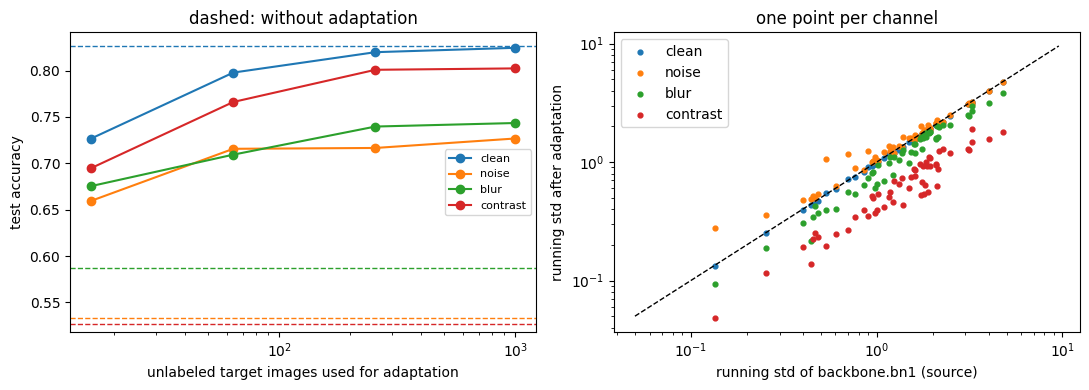

In [33]:
# Provided: accuracy under distribution shift, with and without adaptation.
CORRUPTIONS = {'clean': lambda x: x, 'noise': gaussian_noise, 'blur': gaussian_blur, 'contrast': low_contrast}
NUM_UNLABELED = [16, 64, 256, 1000]
shift_model.eval()
show_images([fn(data['x_test'][:8]) for fn in CORRUPTIONS.values()], list(CORRUPTIONS))
plt.show()

shift_rows, adapted_models = [], {}
for corruption, fn in CORRUPTIONS.items():
    x_shift = fn(data['x_test'])
    row = {'corruption': corruption, 'source': accuracy(shift_model, x_shift, data['y_test'])}
    for n in NUM_UNLABELED:
        adapted = adapt_batchnorm(shift_model, x_shift[:n], batch_size=min(n, 200))
        row[f'adapted_{n}'] = accuracy(adapted, x_shift, data['y_test'])
    adapted_models[corruption] = adapted
    row['clip_zero_shot'] = (zero_shot_logits(encode_images(x_shift), text_weights).argmax(dim=1)
                             == data['y_test']).float().mean().item()
    shift_rows.append(row)
    print(f"{corruption:9s}: ResNet-18 {row['source']:.3f} | adapted " +
          ' '.join(f"n={n}: {row[f'adapted_{n}']:.3f}" for n in NUM_UNLABELED) +
          f" | CLIP zero-shot {row['clip_zero_shot']:.3f}")
save_table(shift_rows, 'distribution_shift')
noise_on_clean = accuracy(adapted_models['noise'], data['x_test'], data['y_test'])
print(f"statistics adapted to noise, evaluated on clean images: {noise_on_clean:.3f} "
      f"(source model {shift_rows[0]['source']:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i, corruption in enumerate(CORRUPTIONS):
    rows = shift_rows[i]
    axes[0].plot(NUM_UNLABELED, [rows[f'adapted_{n}'] for n in NUM_UNLABELED], 'o-', color=f'C{i}', label=corruption)
    axes[0].axhline(rows['source'], color=f'C{i}', ls='--', lw=1)
axes[0].set_xscale('log')
axes[0].set_xlabel('unlabeled target images used for adaptation')
axes[0].set_ylabel('test accuracy')
axes[0].set_title('dashed: without adaptation')
axes[0].legend(fontsize=8, loc='center right')
source_std = shift_model.backbone.bn1.running_var.sqrt().cpu()
active = source_std > 0.05   # leave out the few channels that are almost always zero
for i, corruption in enumerate(CORRUPTIONS):
    adapted_std = adapted_models[corruption].backbone.bn1.running_var.sqrt().cpu()
    axes[1].scatter(source_std[active], adapted_std[active], s=12, color=f'C{i}', label=corruption)
lim = [0.05, source_std.max().item() * 2]
axes[1].plot(lim, lim, 'k--', lw=1)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('running std of backbone.bn1 (source)')
axes[1].set_ylabel('running std after adaptation')
axes[1].set_title('one point per channel')
axes[1].legend()
fig.tight_layout()
plt.show()


In [34]:
# Provided check: distribution shift and adaptation.
rows = {r['corruption']: r for r in shift_rows}
for corruption in ['noise', 'blur', 'contrast']:
    assert rows[corruption]['source'] <= rows['clean']['source'] - 0.15, corruption
    assert rows[corruption]['adapted_1000'] >= rows[corruption]['source'] + 0.08, corruption
assert abs(rows['clean']['adapted_1000'] - rows['clean']['source']) < 0.02
assert noise_on_clean < rows['clean']['source'] - 0.2
print('Distribution shift check passed')


Distribution shift check passed


#### Provided: Domain Generalization with Corruption Augmentation

Re-estimating batch normalization statistics needs unlabeled images of the
target domain. The cell below follows the other approach: it fine-tunes a new
ResNet-18 in the same way as `full_low_lr` with 500 images per class, but
replaces one third of the training images by a noisy version and one third by
a low-contrast version, each with a random strength. It never sees a blurred
image, so blur acts as an unseen target domain. The model is then evaluated on
every corruption, without and with batch normalization adaptation to 1,000
unlabeled test images. The results are saved to
`logs/domain_generalization.csv`, and you will interpret them in Question 2.7.

**Lecture Connection**

> Training with one or more available source domains  
> No target-domain training examples  
> Source diversity and augmentation as possible strategies  
> Evaluation on held-out target domains  
> *(Lec09 Transfer Learning and Adaptation, p. 37)*

> Target-domain data available during adaptation  
> Unsupervised adaptation with unlabeled target examples  
> *(Lec09 Transfer Learning and Adaptation, p. 35)*

**Expected Check:** The corruption-augmented model is at least `0.05` more
accurate on blur than the model of Part 1, at least `0.1` more accurate on
noise and on low contrast, and at most `0.03` less accurate on clean images.


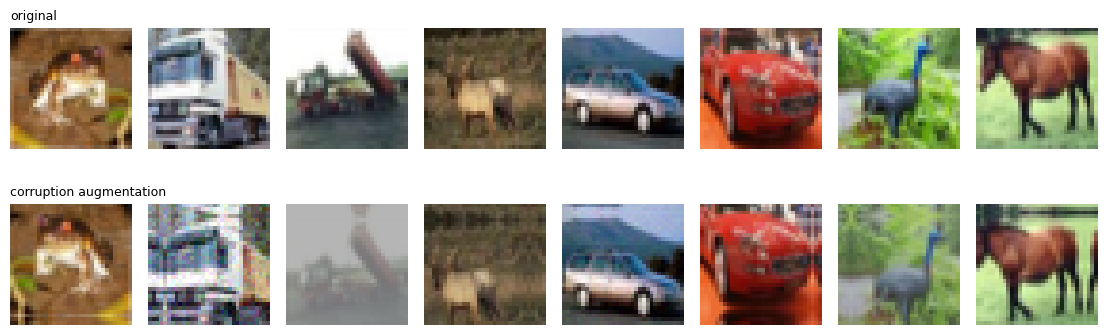

clean     (seen in training: True ) | Part 1 model 0.827, + BN adaptation 0.825 | corruption-augmented 0.834, + BN adaptation 0.831
noise     (seen in training: True ) | Part 1 model 0.533, + BN adaptation 0.727 | corruption-augmented 0.758, + BN adaptation 0.758
blur      (seen in training: False) | Part 1 model 0.587, + BN adaptation 0.743 | corruption-augmented 0.665, + BN adaptation 0.760
contrast  (seen in training: True ) | Part 1 model 0.526, + BN adaptation 0.802 | corruption-augmented 0.802, + BN adaptation 0.813


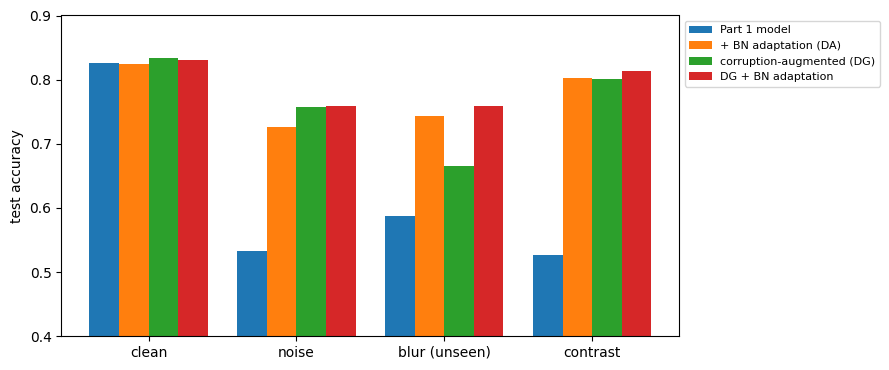

In [35]:
# Provided: train with noise and low-contrast augmentation, and evaluate on every corruption.
def corruption_augment(x):
    """Provided: crops and flips, then noise or low contrast with random strength (a third of the images each)."""
    x = random_crop_flip(x)
    n = x.shape[0]
    pick = torch.rand(n, 1, 1, 1, device=x.device)
    std = torch.empty(n, 1, 1, 1, device=x.device).uniform_(0.0, 0.12)
    noisy = (x + std * torch.randn_like(x)).clamp(0, 1)
    factor = torch.empty(n, 1, 1, 1, device=x.device).uniform_(0.2, 1.0)
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    low = (mean + factor * (x - mean)).clamp(0, 1)
    return torch.where(pick < 1 / 3, noisy, torch.where(pick < 2 / 3, low, x))


show_images([data['x_train'][:8], corruption_augment(data['x_train'][:8])], ['original', 'corruption augmentation'])
plt.show()

torch.manual_seed(SEED)
dg_model = TransferResNet(pretrained=True).to(device)
dg_log, dg_result = finetune(dg_model, 'full', 'cifar10_corruption_augmented_500',
                             balanced_subset(data['y_train'], 500), num_epochs=15, backbone_lr=1e-4,
                             augment=corruption_augment, verbose=False)
dg_rows = []
for corruption, fn in CORRUPTIONS.items():
    x_shift = fn(data['x_test'])
    source = next(r for r in shift_rows if r['corruption'] == corruption)
    row = {'corruption': corruption, 'seen_in_training': corruption in ('clean', 'noise', 'contrast'),
           'source': source['source'], 'source_adapted_1000': source['adapted_1000'],
           'augmented': accuracy(dg_model, x_shift, data['y_test']),
           'augmented_adapted_1000': accuracy(adapt_batchnorm(dg_model, x_shift[:1000]), x_shift, data['y_test'])}
    dg_rows.append(row)
    print(f"{corruption:9s} (seen in training: {str(row['seen_in_training']):5s}) | Part 1 model {row['source']:.3f}, "
          f"+ BN adaptation {row['source_adapted_1000']:.3f} | corruption-augmented {row['augmented']:.3f}, "
          f"+ BN adaptation {row['augmented_adapted_1000']:.3f}")
save_table(dg_rows, 'domain_generalization')

fig, ax = plt.subplots(figsize=(9, 3.8))
keys = [('source', 'Part 1 model'), ('source_adapted_1000', '+ BN adaptation (DA)'),
        ('augmented', 'corruption-augmented (DG)'), ('augmented_adapted_1000', 'DG + BN adaptation')]
for i, (key, label) in enumerate(keys):
    ax.bar(np.arange(len(dg_rows)) + 0.2 * i - 0.3, [r[key] for r in dg_rows], width=0.2, color=f'C{i}', label=label)
ax.set_xticks(range(len(dg_rows)))
ax.set_xticklabels([r['corruption'] + ('' if r['seen_in_training'] else ' (unseen)') for r in dg_rows])
ax.set_ylim(0.4, 0.9)
ax.set_ylabel('test accuracy')
ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), fontsize=8)
fig.tight_layout()
plt.show()


In [36]:
# Provided check: corruption augmentation generalizes to the unseen blur.
rows = {r['corruption']: r for r in dg_rows}
assert rows['blur']['augmented'] >= rows['blur']['source'] + 0.05
for corruption in ['noise', 'contrast']:
    assert rows[corruption]['augmented'] >= rows[corruption]['source'] + 0.1, corruption
assert rows['clean']['augmented'] >= rows['clean']['source'] - 0.03
print('Domain generalization check passed')


Domain generalization check passed


#### Question 2.7: Domain Adaptation and Domain Generalization [written] (8 points)

---

Answer using the distribution shift and domain generalization results and
plots:

1. How much does each corruption lower the accuracy of the fine-tuned
   ResNet-18, and how much does it lower the zero-shot accuracy of CLIP? Which
   model is more robust to which corruption, and what about their pretraining
   could explain the difference? (2 points)
2. Explain why re-estimating the batch normalization statistics recovers much
   of the accuracy without any labels or weight updates, using the plot of the
   running standard deviations of `backbone.bn1`. How many unlabeled images are
   needed, and why does the model adapted to noise fail on clean images?
   (3 points)
3. Which of the two methods, batch normalization adaptation and corruption
   augmentation, is domain adaptation and which is domain generalization, and
   what does each need from the target domain? Compare them on the unseen blur
   and explain why augmentation helps on blur, although less than on noise and
   low contrast. Finally, describe one kind of distribution shift that neither
   method can fix. (3 points)

$\color{blue}{\textit Your Answer:}$

<!-- ANSWER_START: 2.7 -->
1. Noise, blur, contrast에 따른 clean 대비 정확도 하락은 ResNet-18에서 각각 29.4, 24.0, 30.1%p, CLIP에서 40.4, 23.2, 10.5%p였다. CLIP은 blur와 contrast에서 더 강건했지만 noise에서는 ResNet보다 정확도가 낮고 하락 폭도 컸다. CLIP의 광범위한 이미지·텍스트 사전학습이 다양한 영상 조건에 대한 강건성에 기여했을 가능성이 있지만, Gaussian noise까지 강건함을 보장하지는 않는다.

2. 이미지 변형은 activation 분포를 바꾸어 기존 BN 통계와 불일치를 만든다. 산점도에서도 noise는 여러 채널의 표준편차를 증가시키고 blur와 contrast는 감소시키는 경향을 보였다. Target 이미지로 BN 통계를 다시 추정하면 이 불일치를 줄이므로 라벨이나 가중치 갱신 없이도 정확도가 회복된다.
1,000개 사용 시 noise, blur, contrast에서 각각 19.4, 15.6, 27.6%p가 회복됐으며, 256개만으로도 1,000개 결과와 약 1.0%p 이내였다. 반면 noise에 맞춘 통계는 clean 분포와 맞지 않아 clean 정확도가 82.7%에서 47.7%로 하락했다.

3. BN 적응은 라벨 없는 target 이미지를 사용하는 domain adaptation(DA)이고, corruption augmentation은 target 데이터 없이 source 데이터의 다양성을 높이는 domain generalization(DG)이다.
학습에서 보지 않은 blur에서 기존 모델, DA, DG, DG+DA의 정확도는 각각 58.7%, 74.3%, 66.5%, 76.0%였다. 증강으로 다양한 영상 조건에 견디는 특징을 학습하여 blur에도 도움이 됐지만, 직접 학습한 noise·contrast보다 개선 폭이 작았다. 두 방법 모두 기존 출력 클래스에 없는 새로운 클래스의 등장을 해결할 수는 없다.
<!-- ANSWER_END: 2.7 -->

---


## Submission Checklist

- Fill in the student ID and name.
- Complete every numbered TODO and all four written questions.
- Do not use `torchvision.transforms`, `F.cosine_similarity`, `CLIPModel.forward` (or `logits_per_image`), the `peft` library, or `sklearn` in submitted implementations.
- Confirm that all provided checks pass.
- Confirm that the `logs/` directory contains the CSV logs of your runs, `frozen_features.csv`, `transfer_comparison.csv`, `zero_shot.csv`, `few_shot.csv`, `peft_comparison.csv`, `distribution_shift.csv`, and `domain_generalization.csv`.
- Make sure every plot and image grid is visible in the submitted notebook.
- Restart the runtime and run every cell from top to bottom before submission.
